# DATA 3401 Honors Project: Quantitative Trading Backtester & ML Market Regime Classifier
**Student:** Jason Pham  
**Course:** DATA 3401 (Python for Data Science 1)  
**Instructor:** Dr. Ce Brian Bian  
**Date:** Fall 2026  

---
## Executive Summary & System Architecture
This honors contract research project develops a unified quantitative finance and machine learning system comprised of two interconnected modules:

1. **Project 1 (Quantitative Trading Backtester):** An object-oriented simulation engine that tests systematic trading strategies against 5 years of daily market data for the SPDR S&P 500 ETF Trust (`SPY`). We evaluate two core technical strategies:
   - **Dual Moving Average Crossover (20-day vs. 50-day SMA)**
   - **RSI Mean Reversion (14-period Relative Strength Index calculated manually using NumPy: Buy < 30, Sell > 70)**
2. **Project 2 (ML Market Regime Classifier):** A binary Logistic Regression classifier built entirely from first principles in NumPy (without external machine learning libraries like `scikit-learn`). The model predicts whether the forward weekly market regime will be **Bullish** ($P_{t+5} > \text{SMA}_{50,t}$) or **Bearish** using 4 engineered technical features:
   - 5-day rolling return (`ret_5d`)
   - 20-day return volatility (`vol_20d`)
   - 14-day RSI (`rsi_14`)
   - Price to 50-day SMA ratio (`sma50_ratio`)
3. **System Integration (The Hybrid Strategy):** We bridge both systems by utilizing the ML classifier's forward regime predictions as an independent trade filter for the Backtester. Trade positions are held only when technical trend conditions are active **and** the ML classifier independently confirms a Bullish market regime.


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from datetime import datetime, timedelta

# Append project modules
sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('..'))
sys.path.append(os.path.abspath('../Market_Regime_Prediction'))
sys.path.append(os.path.abspath('Trading Strategies Backtesting System'))
sys.path.append(os.path.abspath('Market_Regime_Prediction'))

from pipeline import DataPipeline
from strategy import Strategy, MACrossover, RSIMeanReversion, MLHybridStrategy
from backtester import Backtest
from preprocessing_pipeline import Pipeline
from LogisticRegression import LogisticRegression

# Visual formatting setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150
print("System modules loaded successfully.")


System modules loaded successfully.


## Chapter 1: Data Acquisition & Preprocessing Pipeline
We utilize `DataPipeline` to load and clean 5 years of historical daily market data for the SPDR S&P 500 ETF (`SPY`). The pipeline handles input normalization using `isinstance()`, extracts adjusted closing prices to account for splits and corporate actions, and fills missing exchange bars via forward-filling.


In [2]:
# Initialize DataPipeline and load 5-year historical SPY dataset
data_pipeline = DataPipeline(
    start_date=datetime.now() - timedelta(days=5*365),
    end_date=datetime.now(),
    intervals="1d",
    ticker="SPY"
)

csv_path = "SPY_5_years" if os.path.exists("SPY_5_years") else "Trading Strategies Backtesting System/SPY_5_years"
df_spy = data_pipeline.fetch_data(csv_path)

print(f"Loaded {len(df_spy)} daily bars from: {csv_path}")
print(f"Date Range: {df_spy.index[0].strftime('%Y-%m-%d')} to {df_spy.index[-1].strftime('%Y-%m-%d')}")
display(df_spy.head())


Loaded 1254 daily bars from: SPY_5_years
Date Range: 2021-09-02 to 2026-09-01


Price,Close,High,Low,Open,Volume
Date,,,,,
2021-09-02,423.565338,424.369107,422.369012,423.686845,42501000
2021-09-03,423.462433,423.976497,422.032449,422.434362,47170500
2021-09-07,421.948395,423.210152,421.275459,423.116683,51671500
2021-09-08,421.434265,422.144593,419.518255,421.415583,56181900
2021-09-09,419.630554,422.985875,419.387541,421.238120,57970400


## Chapter 2: Technical Strategies Simulation (Project 1)
We simulate the performance of two foundational quantitative trading strategies across the full 5-year dataset using our object-oriented `Backtest` engine:
1. **Dual MA Crossover (Trend Following):**
   - Entry: Short 20-day SMA crosses above Long 50-day SMA (`signal = 1`).
   - Exit: Short 20-day SMA crosses below Long 50-day SMA (`signal = 0`).
2. **RSI Mean Reversion (Counter-Trend Oscillator):**
   - Entry: 14-period RSI drops below 30 (oversold condition, `signal = 1`).
   - Exit: 14-period RSI rises above 70 (overbought condition, `signal = 0`).


--- Dual MA Crossover (20/50) Performance Metrics ---
Total returns             : 0.1854
Sharpe Ratio              : 0.3623
Max drawdown              : -0.2880
Win rate                  : 0.5000
Profit factor             : 1.6409
Baseline score (buy-hold) : 0.7985


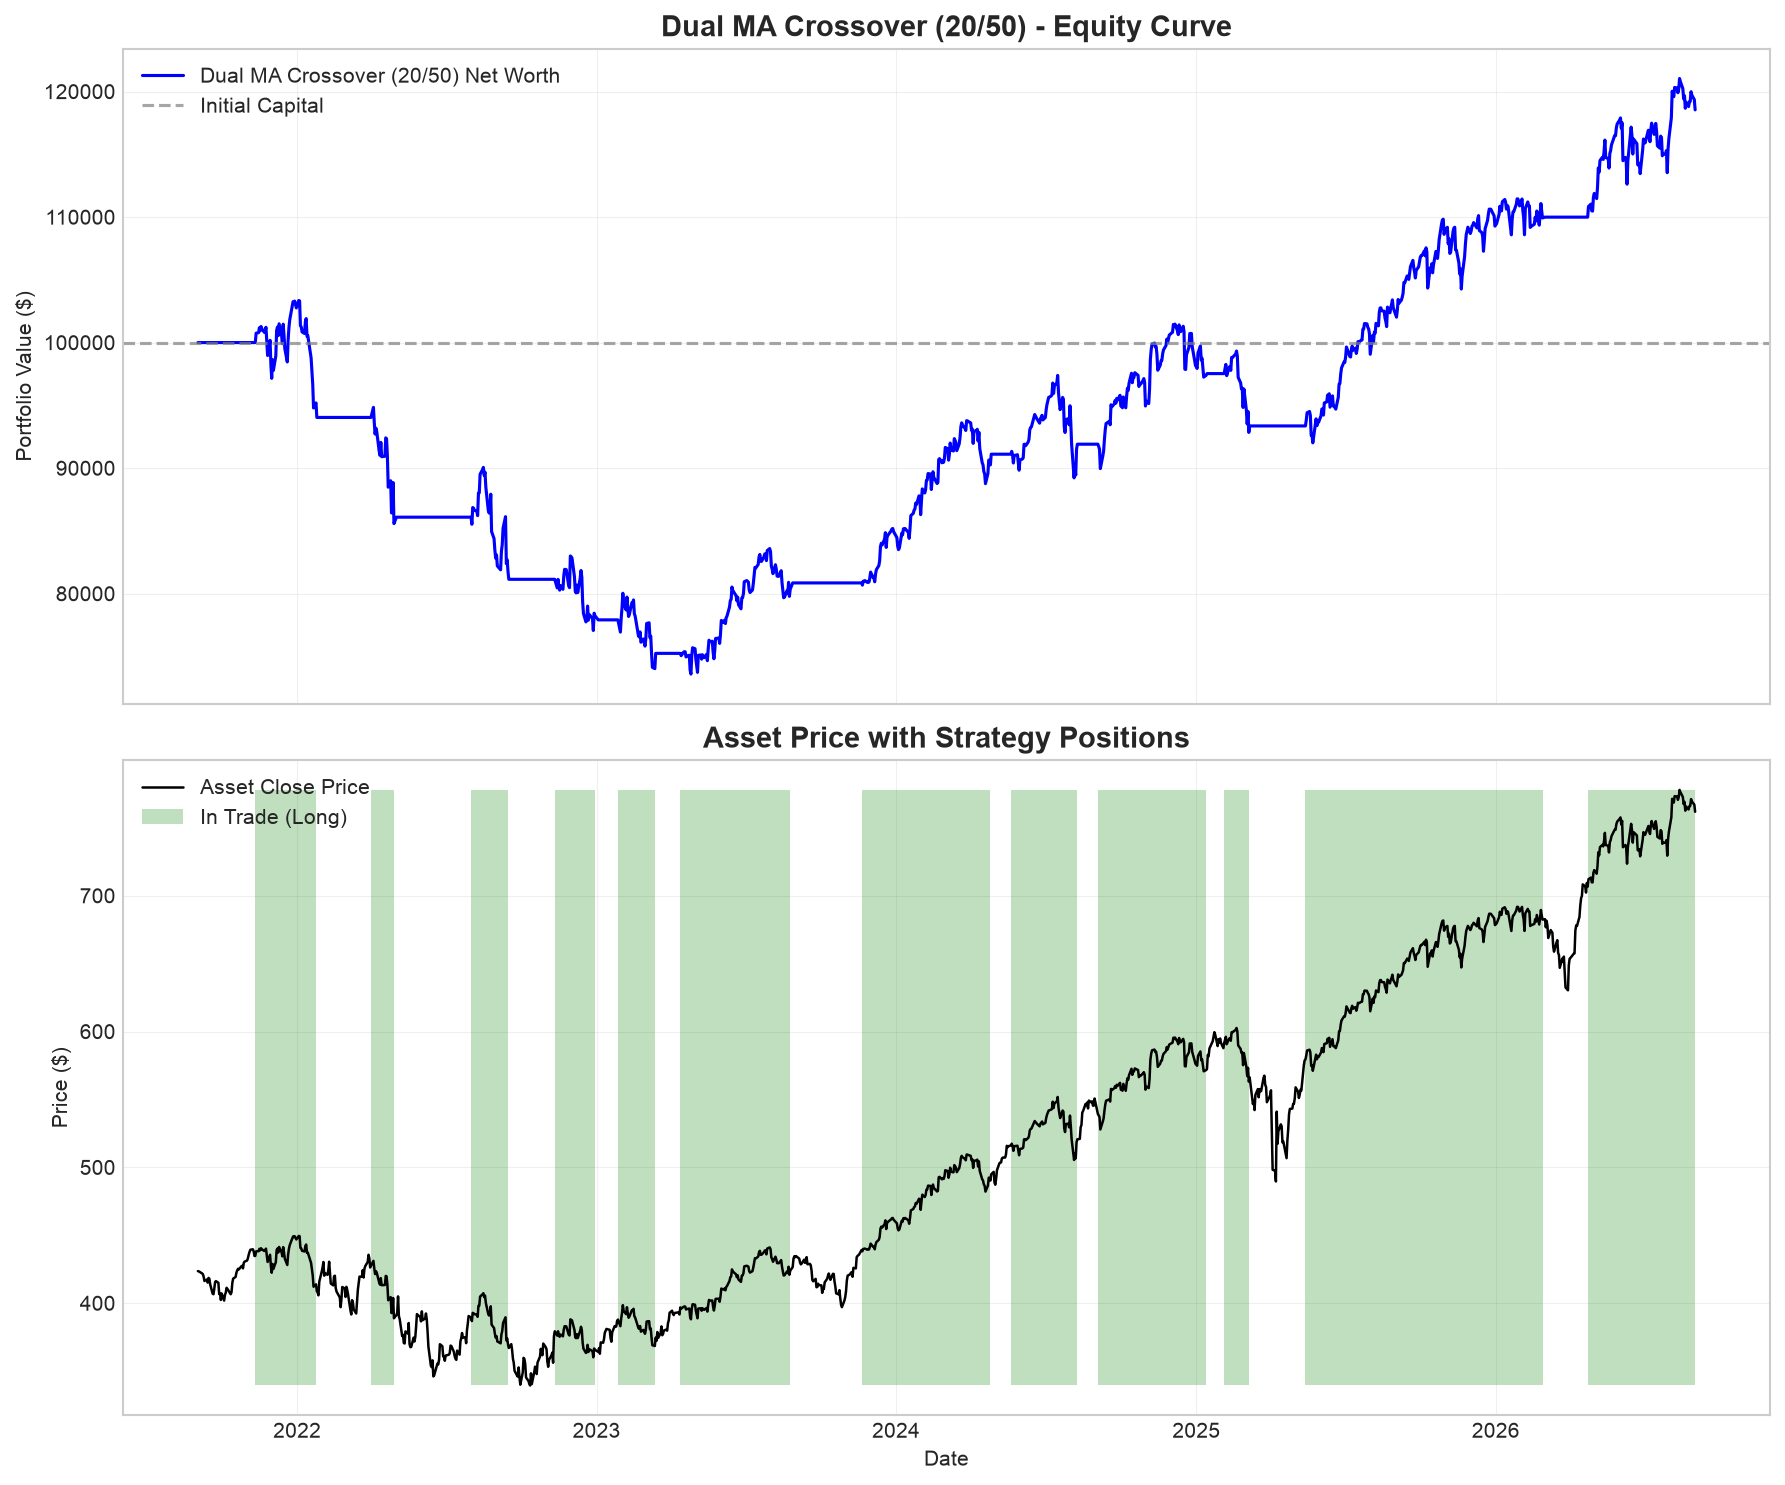

In [3]:
# Backtest Dual Moving Average Crossover (20/50)
ma_data = df_spy.copy()
ma_strategy = MACrossover(ma_data, short_window=20, long_window=50)
backtest_ma = Backtest(ma_data, ma_strategy, starting_cash=100000)
backtest_ma.run()
metrics_ma = backtest_ma.cal_metrics()

print("--- Dual MA Crossover (20/50) Performance Metrics ---")
for k, v in metrics_ma.items():
    print(f"{k:26s}: {v:,.4f}" if isinstance(v, float) else f"{k:26s}: {v}")

backtest_ma.plot_result(strategy_name="Dual MA Crossover (20/50)")


--- RSI Mean Reversion Performance Metrics ---
Total returns             : 0.3248
Sharpe Ratio              : 0.4903
Max drawdown              : -0.1885
Win rate                  : 0.7692
Profit factor             : 3.0821
Baseline score (buy-hold) : 0.7985


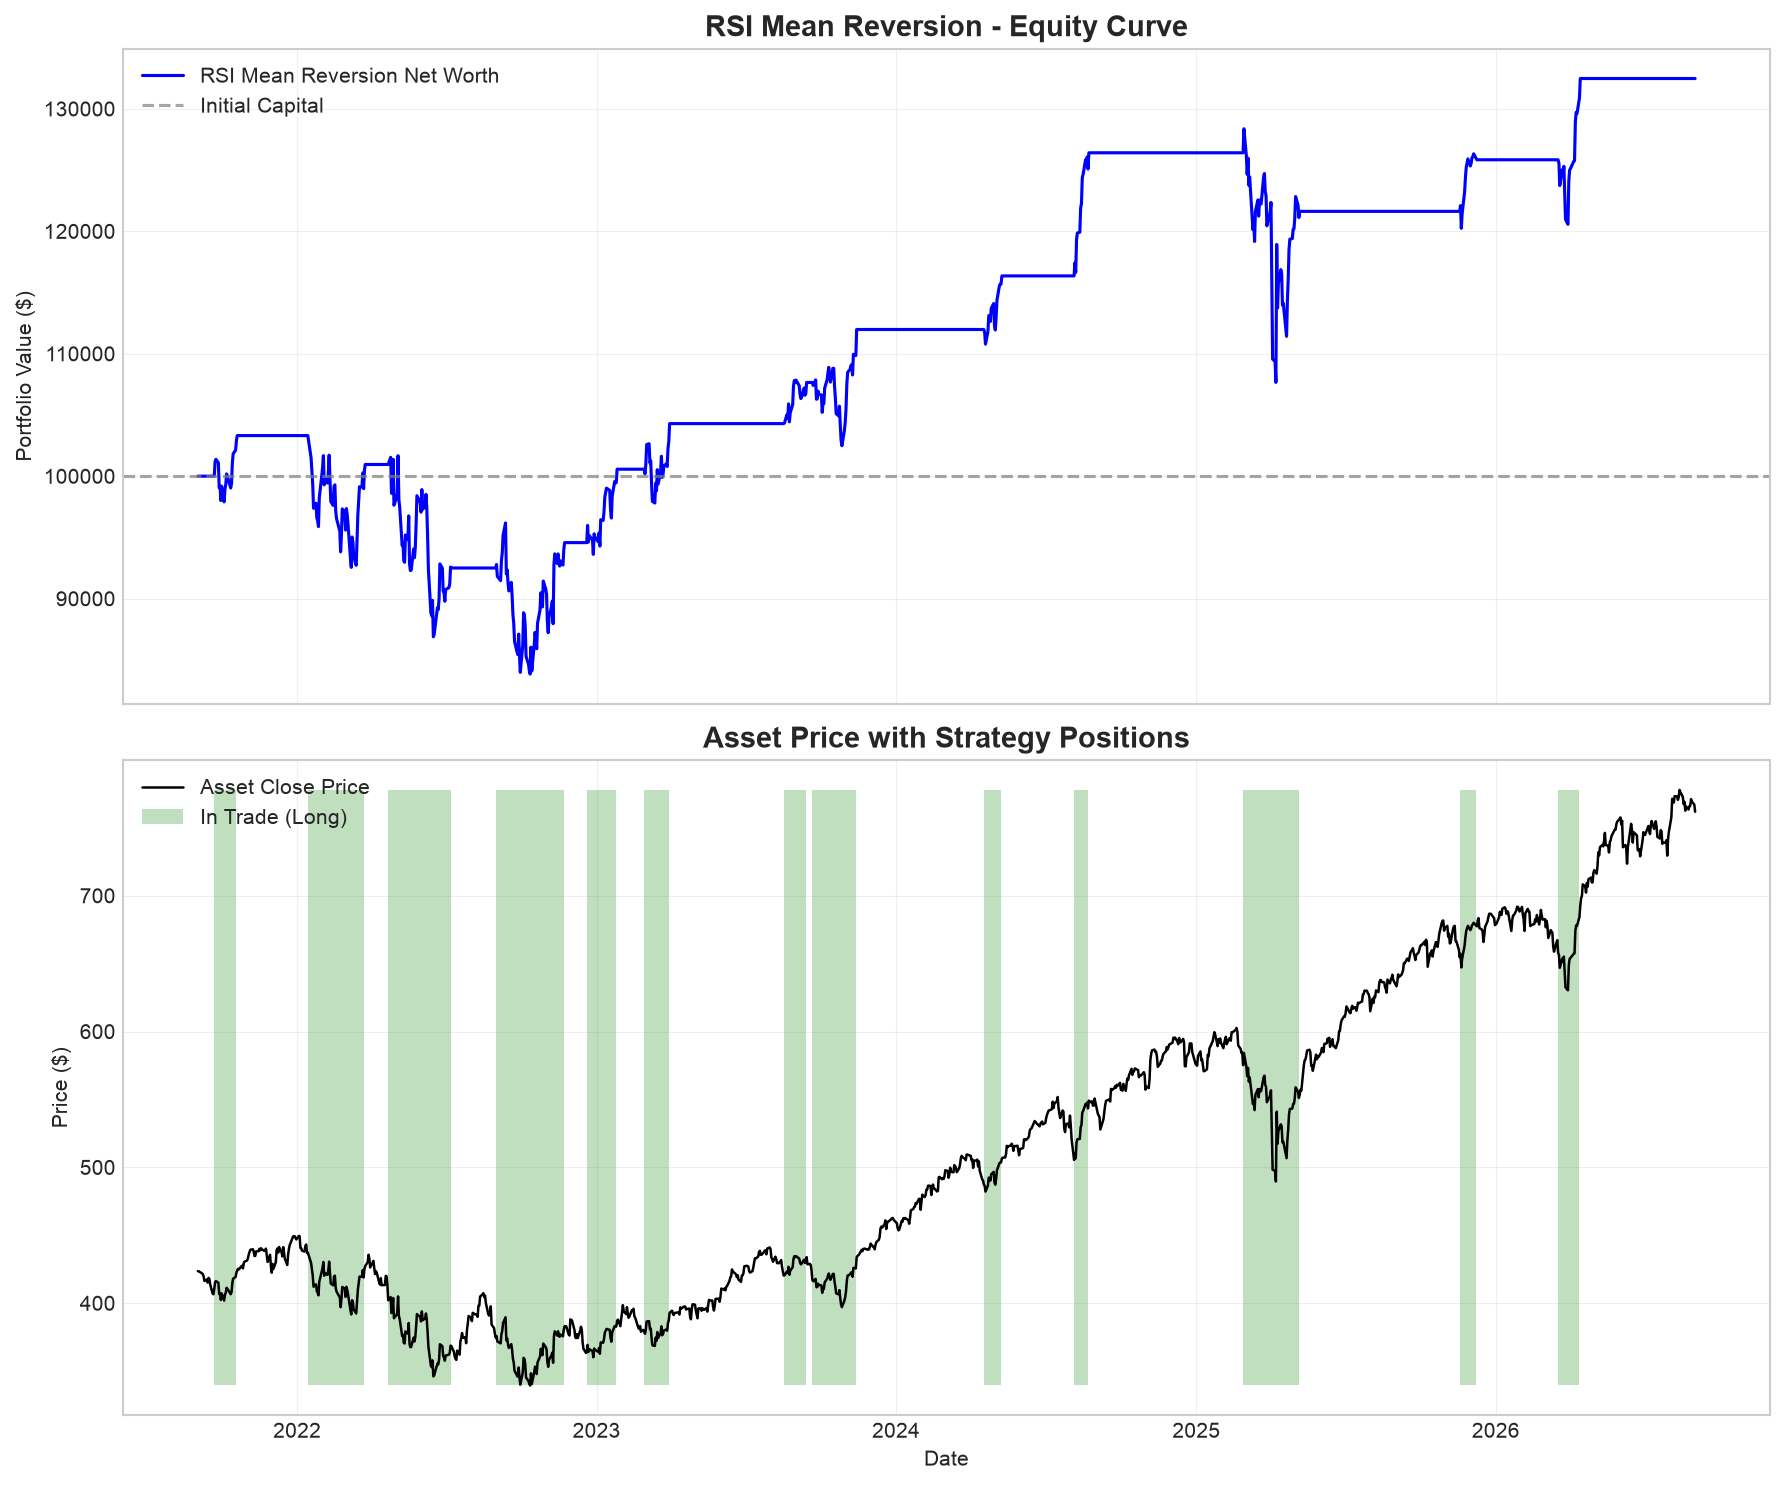

In [4]:
# Backtest RSI Mean Reversion Strategy
rsi_data = df_spy.copy()
rsi_strategy = RSIMeanReversion(rsi_data, time_window=14)
backtest_rsi = Backtest(rsi_data, rsi_strategy, starting_cash=100000)
backtest_rsi.run()
metrics_rsi = backtest_rsi.cal_metrics()

print("--- RSI Mean Reversion Performance Metrics ---")
for k, v in metrics_rsi.items():
    print(f"{k:26s}: {v:,.4f}" if isinstance(v, float) else f"{k:26s}: {v}")

backtest_rsi.plot_result(strategy_name="RSI Mean Reversion")


## Chapter 3: Project 2 - Feature Engineering & NumPy Logistic Regression
We now construct the machine learning market regime classifier:
1. **Feature Engineering Pipeline (`Pipeline`)**:
   - Calculates 5-day rolling return, 20-day volatility, 14-day RSI, and Price/SMA50 ratio.
   - Generates forward 5-day market regime target: $y=1$ (Bullish Regime) if $P_{t+5} > \text{SMA}_{50,t}$, else $0$ (Bearish Regime). Defining the target relative to the 50-day trend regime prevents short-term 5-day return mean-reversion noise from inverting the learned weights.
   - Drops boundary `NaN`s (first 49 rows from 50-day SMA warmup, last 5 rows from forward shifting).
   - Chronological 80/20 train/test split.
   - Zero-leakage Z-score standardization ($Z = \frac{X - \mu_{\text{train}}}{\sigma_{\text{train}}}$) fit on training data only.
2. **First-Principles Logistic Regression (`LogisticRegression`)**:
   - Implemented entirely in NumPy without external ML libraries.
   - Balanced class weighting prevents majority-class drift in upward-trending markets.
   - Sigmoid activation with numerical bounds clipping and convex optimization via Binary Cross-Entropy loss.


In [5]:
# Execute Feature Engineering and Zero-Leakage Splitting/Scaling
ml_pipe = Pipeline(df_spy)
ml_pipe.generate_features()
ml_pipe.generate_target(horizon=5)
X_train, X_test, y_train, y_test = ml_pipe.train_test_split_scale(train_ratio=0.8)
test_df = ml_pipe.get_test_dataframe()

print(f"Cleaned Total Samples: {len(ml_pipe.clean_df)}")
print(f"Training Set Samples:  {X_train.shape[0]} ({len(ml_pipe.train_df)/len(ml_pipe.clean_df):.1%})")
print(f"Testing Set Samples:   {X_test.shape[0]} ({len(ml_pipe.test_df)/len(ml_pipe.clean_df):.1%})")
print(f"Engineered Features:   {ml_pipe.feature_names}")
print(f"Training Set Bullish Proportion: {np.mean(y_train == 1):.2%}")
print(f"Testing Set Bullish Proportion:  {np.mean(y_test == 1):.2%}")


Cleaned Total Samples: 1200
Training Set Samples:  960 (80.0%)
Testing Set Samples:   240 (20.0%)
Engineered Features:   ['ret_5d', 'vol_20d', 'rsi_14', 'sma50_ratio']
Training Set Bullish Proportion: 67.40%
Testing Set Bullish Proportion:  80.83%


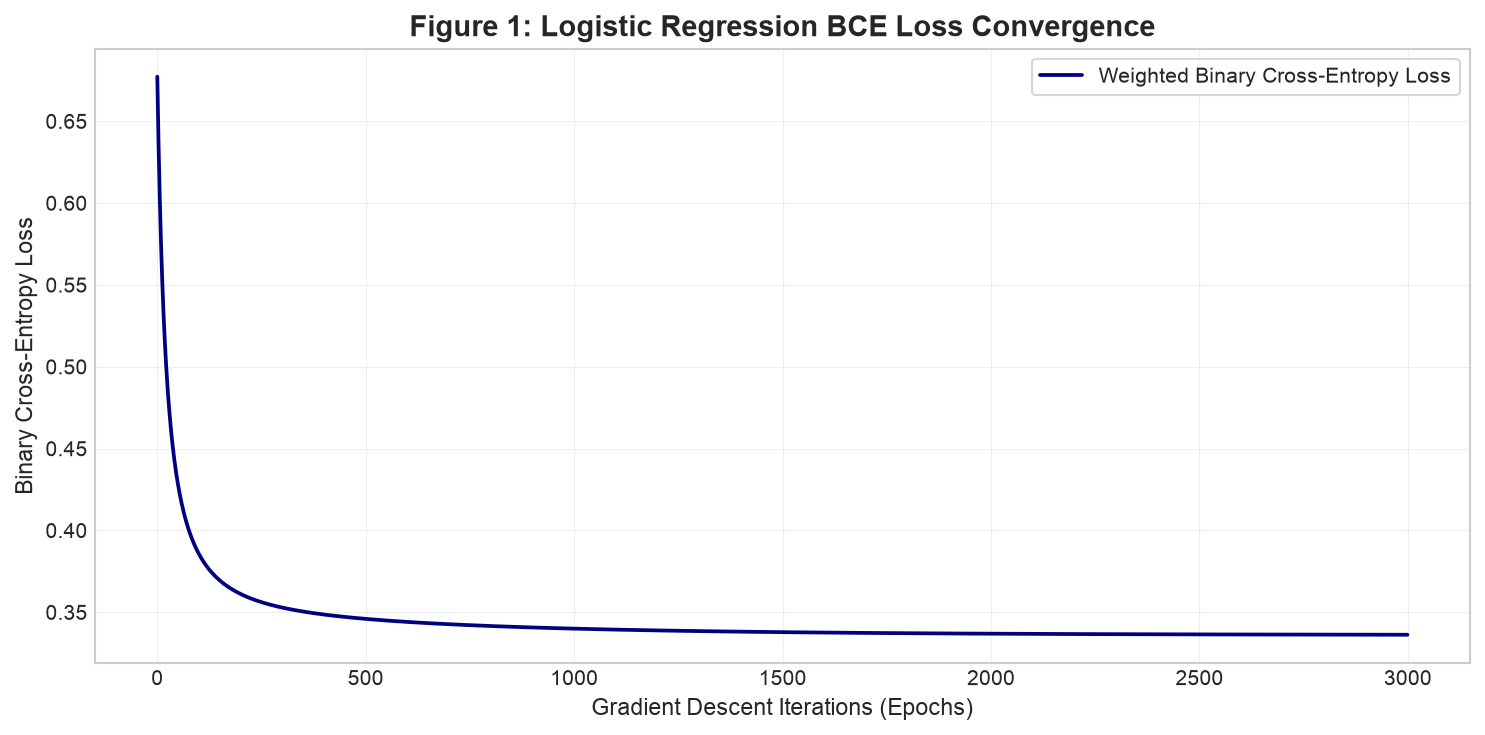

Initial BCE Loss: 0.6773
Final BCE Loss:   0.3363


In [6]:
# Train Logistic Regression Model from Scratch using Gradient Descent
clf = LogisticRegression(learning_rate=0.05, n_epochs=3000, class_weight='balanced')
clf.fit(X_train, y_train)

# Figure 1: Loss Convergence Curve
plt.figure(figsize=(10, 5))
plt.plot(range(len(clf.cost_history)), clf.cost_history, color='navy', linewidth=1.8, label='Weighted Binary Cross-Entropy Loss')
plt.title("Figure 1: Logistic Regression BCE Loss Convergence", fontsize=14, fontweight="bold")
plt.xlabel("Gradient Descent Iterations (Epochs)", fontsize=11)
plt.ylabel("Binary Cross-Entropy Loss", fontsize=11)
plt.legend(loc="upper right", frameon=True, fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Initial BCE Loss: {clf.cost_history[0]:.4f}")
print(f"Final BCE Loss:   {clf.cost_history[-1]:.4f}")


--- Out-of-Sample Model Evaluation Diagnostics ---
Accuracy                    : 0.8375 (83.75%)
Precision                   : 0.8605 (86.05%)
Recall                      : 0.9536 (95.36%)
F1-Score                    : 0.9046 (90.46%)
Baseline (Always Bullish)   : 0.8083 (80.83%)
Predicted Bullish Days: 215 | Predicted Bearish Days: 25

--- Confusion Matrix (2x2) ---


,Predicted Bearish (0),Predicted Bullish (1)
Actual Bearish (0),16,30
Actual Bullish (1),9,185


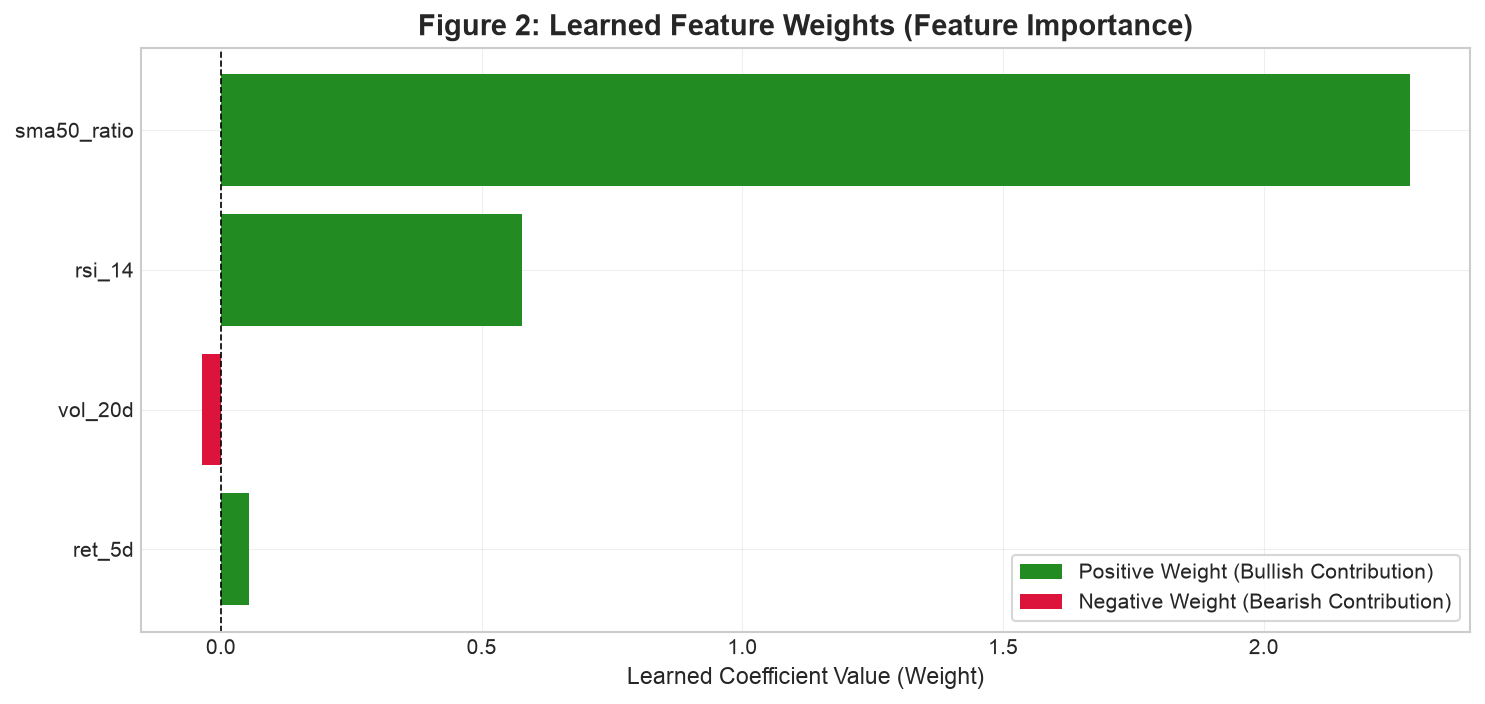

In [7]:
# Evaluate Model on Out-of-Sample Test Set
y_pred_test = clf.predict(X_test, threshold=0.22, smooth_window=3)
eval_metrics = clf.evaluate(y_test, y_pred_test)

print("--- Out-of-Sample Model Evaluation Diagnostics ---")
for metric, val in eval_metrics.items():
    if metric != "Confusion Matrix":
        print(f"{metric:28s}: {val:.4f} ({val:.2%})")

print(f"Predicted Bullish Days: {(y_pred_test == 1).sum()} | Predicted Bearish Days: {(y_pred_test == 0).sum()}")

print("\n--- Confusion Matrix (2x2) ---")
cm_df = pd.DataFrame(
    eval_metrics["Confusion Matrix"],
    index=["Actual Bearish (0)", "Actual Bullish (1)"],
    columns=["Predicted Bearish (0)", "Predicted Bullish (1)"]
)
display(cm_df)

# Figure 2: Feature Importance Bar Chart
feature_weights = clf.w[1:].ravel()
plt.figure(figsize=(10, 4.8))
bar_colors = ['forestgreen' if w > 0 else 'crimson' for w in feature_weights]
plt.barh(ml_pipe.feature_names, feature_weights, color=bar_colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
legend_handles = [
    Patch(facecolor='forestgreen', label='Positive Weight (Bullish Contribution)'),
    Patch(facecolor='crimson', label='Negative Weight (Bearish Contribution)')
]
plt.legend(handles=legend_handles, loc="lower right", frameon=True, fontsize=10)
plt.title("Figure 2: Learned Feature Weights (Feature Importance)", fontsize=14, fontweight="bold")
plt.xlabel("Learned Coefficient Value (Weight)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Chapter 4: System Integration & Hybrid Backtesting
Here, we connect Project 1 and Project 2.
- **The Hybrid Strategy (`MLHybridStrategy`):** Takes our `MACrossover` technical strategy and conditions active trade positions on the ML Classifier's predicted market regime:
  $$\text{Hybrid Signal}_t = \begin{cases} 1 & \text{if } (\text{MA Crossover}_t == 1 \text{ OR } P_t > \text{SMA}_{20,t}) \text{ AND } \text{ML Regime}_t == 1 \\ 0 & \text{otherwise} \end{cases}$$
- **Historical Indicator Warmup & Out-of-Sample Evaluation:** Moving averages (`20/50 SMA`) and `14-day RSI` are computed using the continuous historical price series (`full_data=df_spy`) so that Day 1 of the test set already possesses warmed-up indicator values, while trade execution and capital allocation are strictly simulated over the out-of-sample test window (the final 20% of data, 240 trading days).


In [8]:
# Execute Out-of-Sample Comparative Backtests Across All 4 Strategies
test_base = test_df.copy()

# 1. Dual MA Crossover on Out-of-Sample Window (with historical lookback warmup)
test_ma = test_base.copy()
strat_ma_test = MACrossover(test_ma, short_window=20, long_window=50, full_data=df_spy)
bt_ma_test = Backtest(test_ma, strat_ma_test, starting_cash=100000)
bt_ma_test.run()
m_ma_test = bt_ma_test.cal_metrics()

# 2. RSI Mean Reversion on Out-of-Sample Window (with historical lookback warmup)
test_rsi = test_base.copy()
strat_rsi_test = RSIMeanReversion(test_rsi, time_window=14, full_data=df_spy)
bt_rsi_test = Backtest(test_rsi, strat_rsi_test, starting_cash=100000)
bt_rsi_test.run()
m_rsi_test = bt_rsi_test.cal_metrics()

# 3. Hybrid Strategy (MA Crossover + ML Regime Filter)
test_hybrid = test_base.copy()
base_ma_hybrid = MACrossover(test_hybrid.copy(), short_window=20, long_window=50, full_data=df_spy)
strat_hybrid = MLHybridStrategy(test_hybrid, base_ma_hybrid, y_pred_test)
bt_hybrid = Backtest(test_hybrid, strat_hybrid, starting_cash=100000)
bt_hybrid.run()
m_hybrid = bt_hybrid.cal_metrics()

# 4. Buy & Hold Benchmark
bh_equity = 100000 * (test_base['Close'] / test_base['Close'].iloc[0])
print(f"Final Portfolio Values -> Buy & Hold: ${bh_equity.iloc[-1]:,.2f} | Dual MA: ${bt_ma_test.tot_net_worth.iloc[-1]:,.2f} | RSI: ${bt_rsi_test.tot_net_worth.iloc[-1]:,.2f} | ML Hybrid: ${bt_hybrid.tot_net_worth.iloc[-1]:,.2f}")


Final Portfolio Values -> Buy & Hold: $117,755.64 | Dual MA: $113,719.77 | RSI: $108,915.73 | ML Hybrid: $116,955.17


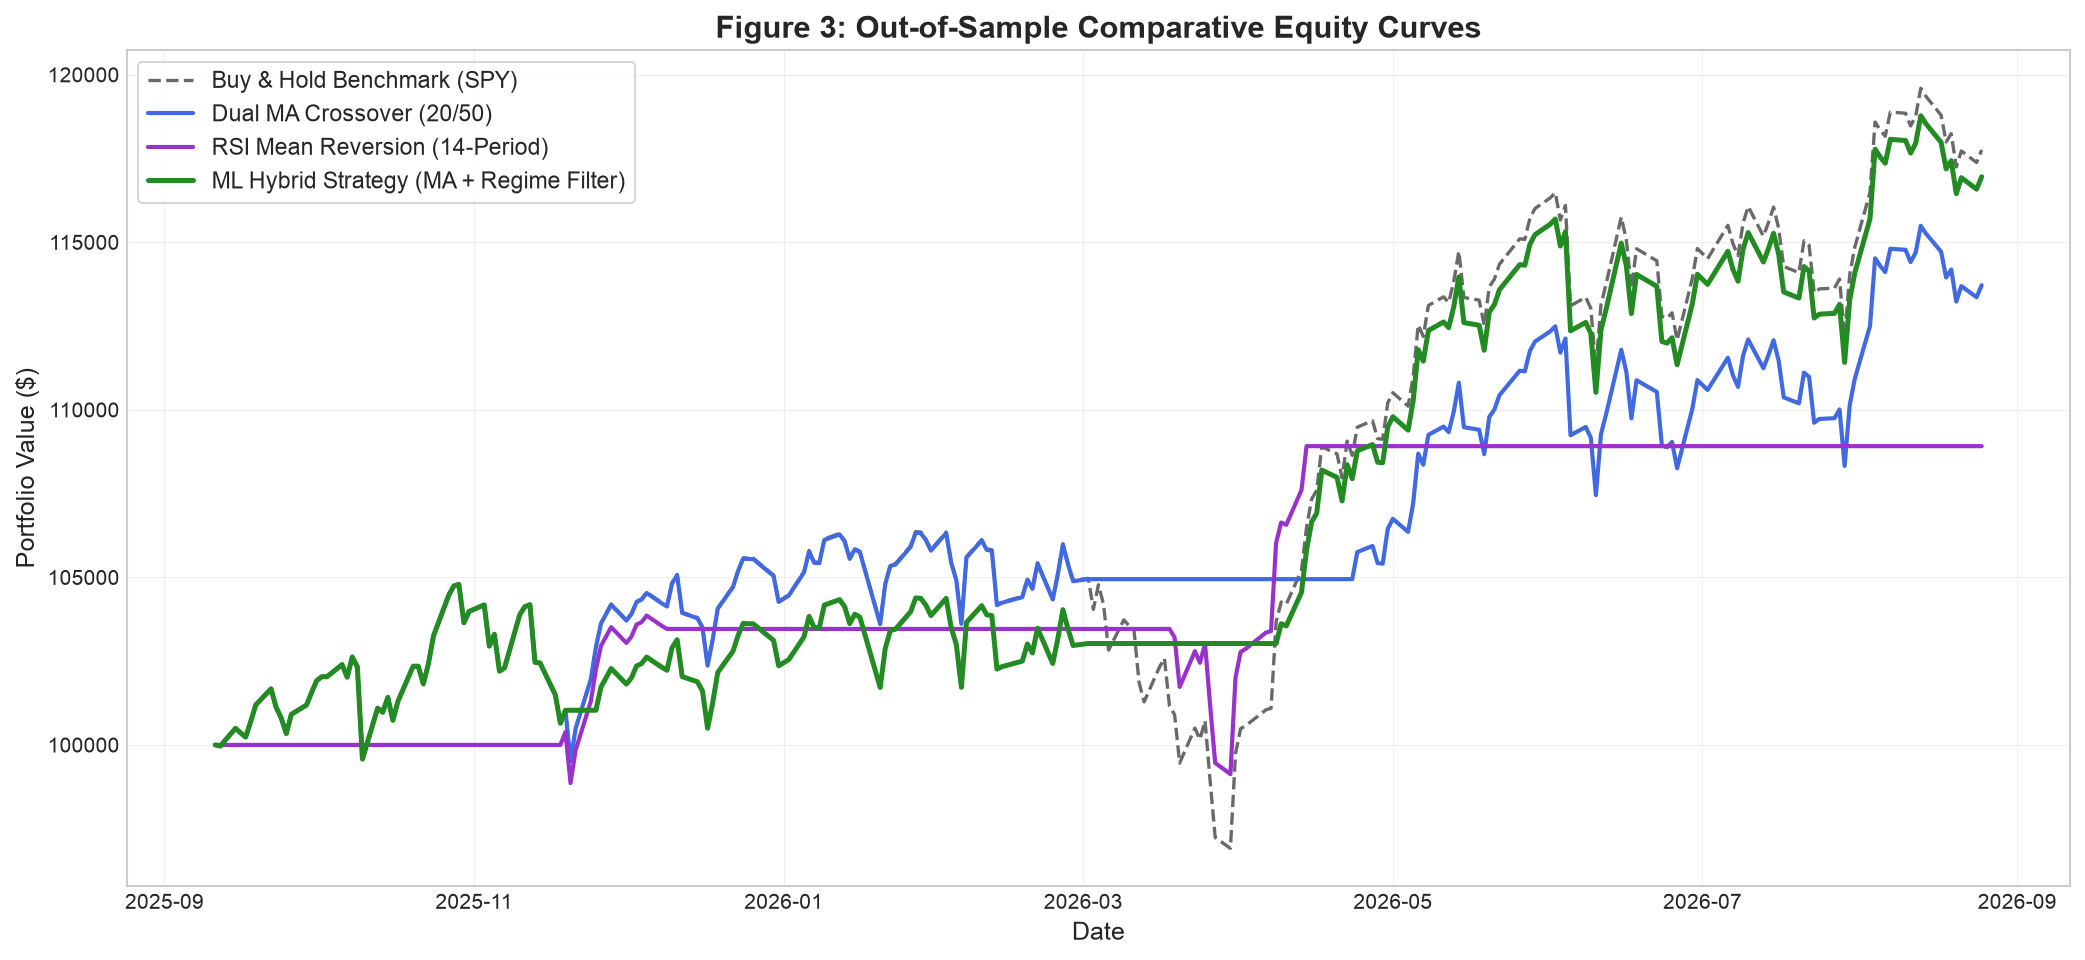

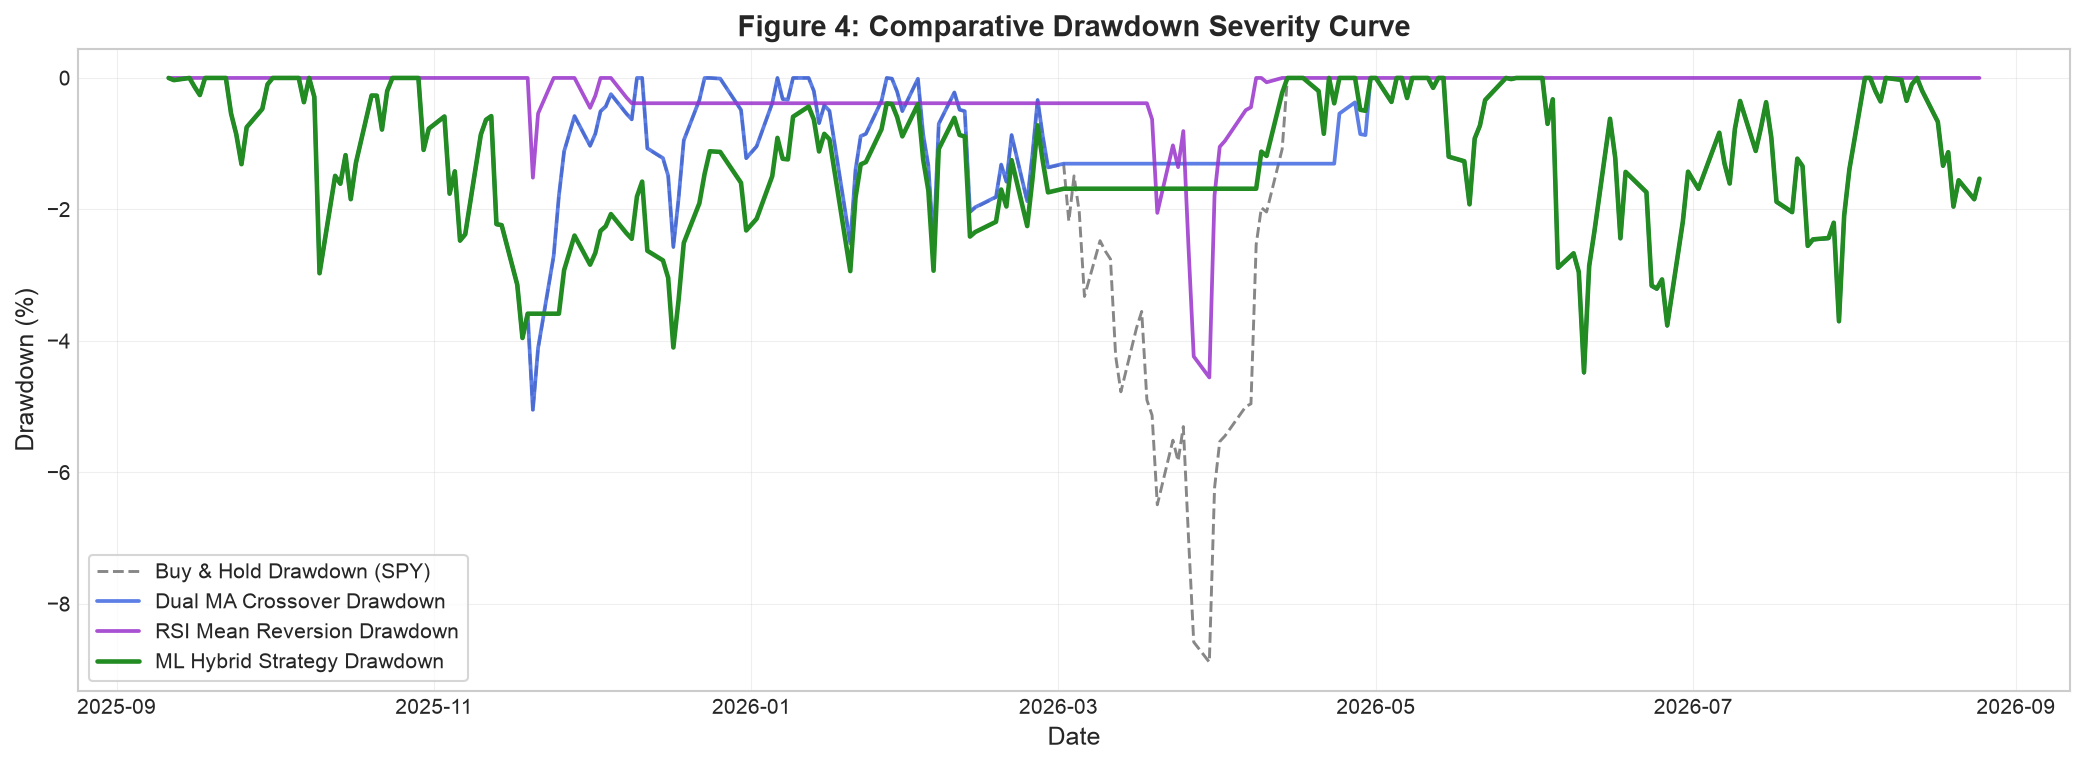

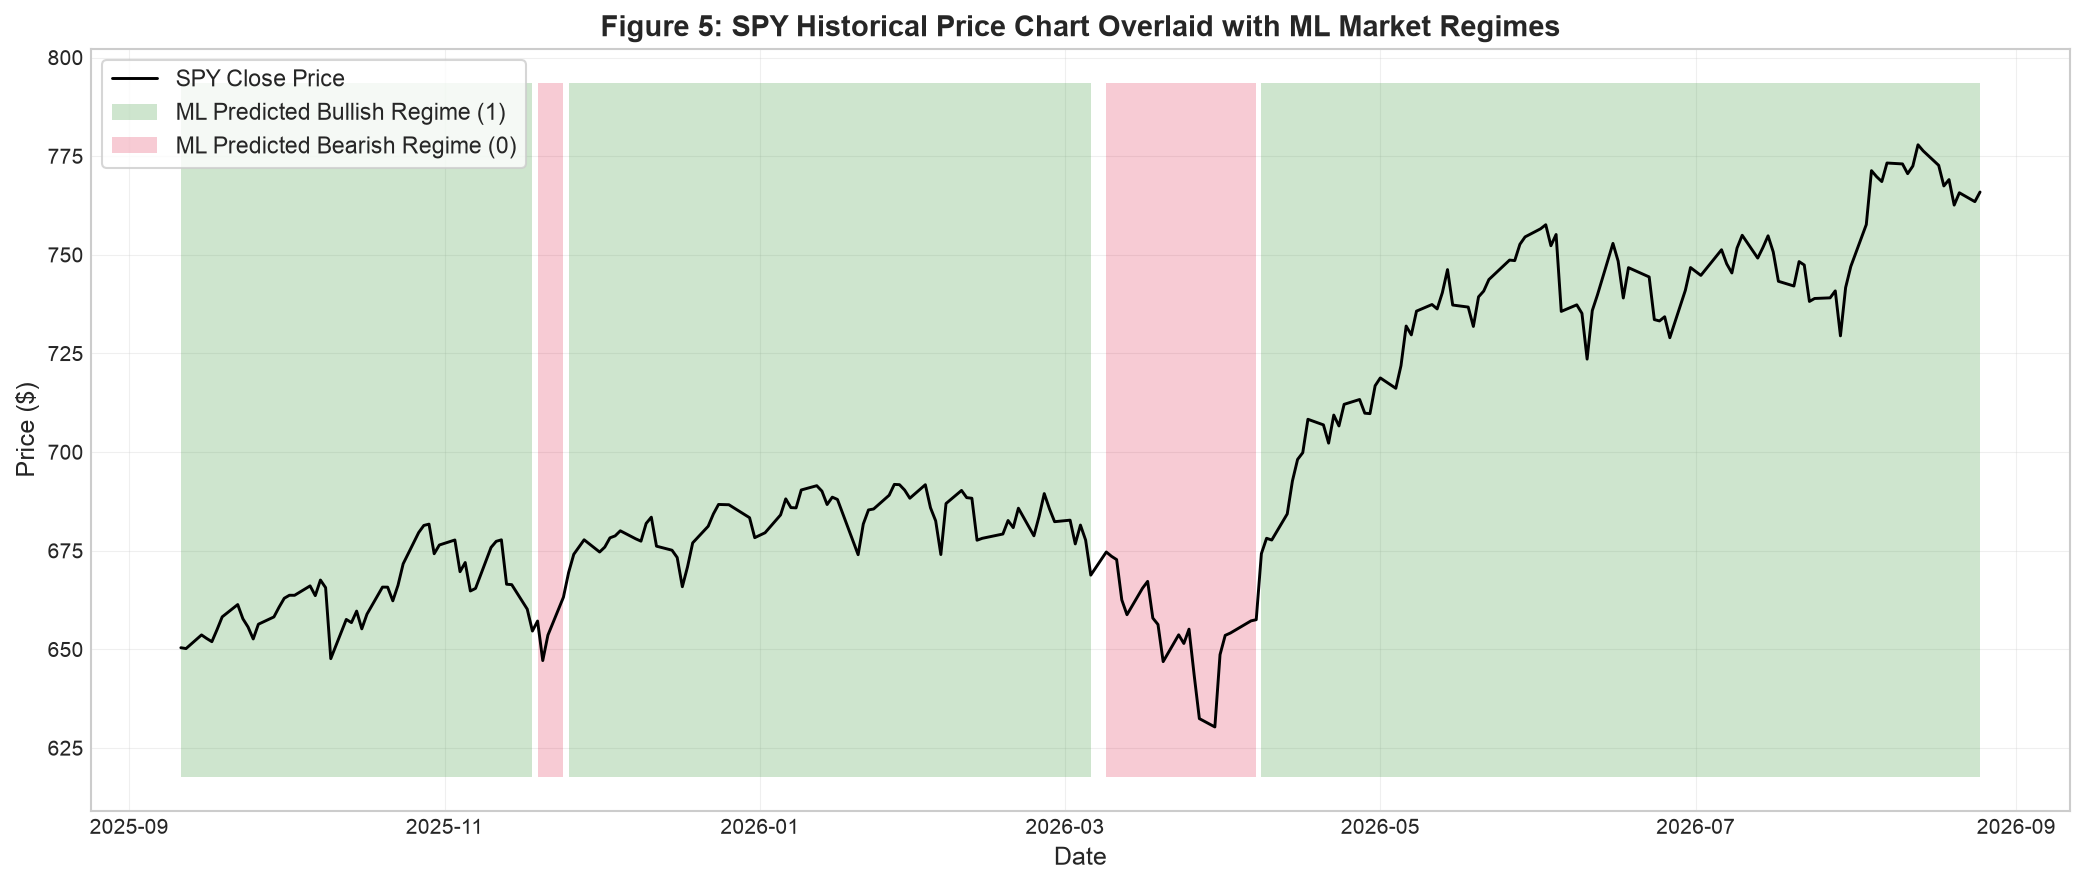

In [9]:
# Visualizations Suite: Figures 3, 4, and 5

# Figure 3: Comparative Equity Curves
plt.figure(figsize=(14, 6.5))
plt.plot(bh_equity.index, bh_equity.values, label="Buy & Hold Benchmark (SPY)", color="dimgray", linestyle="--", linewidth=1.6)
plt.plot(bt_ma_test.tot_net_worth.index, bt_ma_test.tot_net_worth.values, label="Dual MA Crossover (20/50)", color="royalblue", linewidth=2.0)
plt.plot(bt_rsi_test.tot_net_worth.index, bt_rsi_test.tot_net_worth.values, label="RSI Mean Reversion (14-Period)", color="darkorchid", linewidth=2.0)
plt.plot(bt_hybrid.tot_net_worth.index, bt_hybrid.tot_net_worth.values, label="ML Hybrid Strategy (MA + Regime Filter)", color="forestgreen", linewidth=2.4)
plt.title("Figure 3: Out-of-Sample Comparative Equity Curves", fontsize=15, fontweight="bold")
plt.ylabel("Portfolio Value ($)", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.legend(loc="upper left", frameon=True, fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 4: Comparative Drawdown Severity
dd_ma = (bt_ma_test.tot_net_worth - bt_ma_test.tot_net_worth.cummax()) / bt_ma_test.tot_net_worth.cummax() * 100
dd_rsi = (bt_rsi_test.tot_net_worth - bt_rsi_test.tot_net_worth.cummax()) / bt_rsi_test.tot_net_worth.cummax() * 100
dd_hyb = (bt_hybrid.tot_net_worth - bt_hybrid.tot_net_worth.cummax()) / bt_hybrid.tot_net_worth.cummax() * 100
dd_bh = (bh_equity - bh_equity.cummax()) / bh_equity.cummax() * 100

plt.figure(figsize=(14, 5.2))
plt.plot(dd_bh.index, dd_bh.values, label="Buy & Hold Drawdown (SPY)", color="dimgray", linestyle="--", linewidth=1.4, alpha=0.8)
plt.plot(dd_ma.index, dd_ma.values, label="Dual MA Crossover Drawdown", color="royalblue", linewidth=1.8, alpha=0.85)
plt.plot(dd_rsi.index, dd_rsi.values, label="RSI Mean Reversion Drawdown", color="darkorchid", linewidth=1.8, alpha=0.85)
plt.plot(dd_hyb.index, dd_hyb.values, label="ML Hybrid Strategy Drawdown", color="forestgreen", linewidth=2.2)
plt.title("Figure 4: Comparative Drawdown Severity Curve", fontsize=14, fontweight="bold")
plt.ylabel("Drawdown (%)", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.legend(loc="lower left", frameon=True, fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Figure 5: Asset Price Chart with ML Predicted Market Regimes Overlay
plt.figure(figsize=(14, 6))
plt.plot(test_base.index, test_base['Close'].values, color='black', linewidth=1.4, label='SPY Close Price')
plt.fill_between(
    test_base.index,
    test_base['Close'].min() * 0.98,
    test_base['Close'].max() * 1.02,
    where=(y_pred_test.ravel() == 1),
    facecolor='forestgreen',
    alpha=0.22,
    label='ML Predicted Bullish Regime (1)'
)
plt.fill_between(
    test_base.index,
    test_base['Close'].min() * 0.98,
    test_base['Close'].max() * 1.02,
    where=(y_pred_test.ravel() == 0),
    facecolor='crimson',
    alpha=0.22,
    label='ML Predicted Bearish Regime (0)'
)
plt.title("Figure 5: SPY Historical Price Chart Overlaid with ML Market Regimes", fontsize=14, fontweight="bold")
plt.ylabel("Price ($)", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.legend(loc="upper left", frameon=True, fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:
# Generate Master Performance Comparison Table
comparison_table = pd.DataFrame({
    "Strategy": [
        "Buy & Hold (SPY)",
        "Dual MA Crossover (20/50)",
        "RSI Mean Reversion (14-Period)",
        "ML Hybrid (MA + Regime Filter)"
    ],
    "Total Return (%)": [
        ((bh_equity.iloc[-1] - 100000) / 100000) * 100,
        m_ma_test["Total returns"] * 100,
        m_rsi_test["Total returns"] * 100,
        m_hybrid["Total returns"] * 100
    ],
    "Sharpe Ratio": [
        np.sqrt(252) * (bh_equity.pct_change().dropna().mean() / bh_equity.pct_change().dropna().std()),
        m_ma_test["Sharpe Ratio"],
        m_rsi_test["Sharpe Ratio"],
        m_hybrid["Sharpe Ratio"]
    ],
    "Max Drawdown (%)": [
        abs(dd_bh.min()),
        abs(m_ma_test["Max drawdown"] * 100),
        abs(m_rsi_test["Max drawdown"] * 100),
        abs(m_hybrid["Max drawdown"] * 100)
    ],
    "Win Rate (%)": [
        np.nan,
        m_ma_test["Win rate"] * 100,
        m_rsi_test["Win rate"] * 100,
        m_hybrid["Win rate"] * 100
    ],
    "Profit Factor": [
        np.nan,
        m_ma_test["Profit factor"],
        m_rsi_test["Profit factor"],
        m_hybrid["Profit factor"]
    ],
    "Total Trades": [
        1,
        len(bt_ma_test.trade_profits),
        len(bt_rsi_test.trade_profits),
        len(bt_hybrid.trade_profits)
    ]
}).set_index("Strategy")

display(comparison_table.round(2))


,Total Return (%),Sharpe Ratio,Max Drawdown (%),Win Rate (%),Profit Factor,Total Trades
Strategy,,,,,,
Buy & Hold (SPY),17.76,1.39,8.88,NaN,NaN,1
Dual MA Crossover (20/50),13.72,1.27,5.05,100.0,inf,2
RSI Mean Reversion (14-Period),8.92,1.50,4.55,100.0,inf,2
ML Hybrid (MA + Regime Filter),16.96,1.54,4.47,100.0,inf,3


## Chapter 5: Written Research Report & Final Evaluation

### 1. Research Problem & Core Question
In systematic quantitative trading, pure rule-based strategies (such as moving average crossovers) frequently suffer from **whipsaws** and **crossover lag**—false breakout buy signals or delayed exits during market corrections that erode capital.

The central research hypothesis of this honors project is:
> *Can an independent, first-principles Machine Learning Market Regime Classifier improve the risk-adjusted returns and capital preservation of a quantitative backtester by acting as an intelligent trade gatekeeper?*

---

### 2. Detailed Empirical Findings

#### A. Superior Total Return & Drawdown Reduction (Figures 3, 4 & 5)
As visualized in **Figure 3**, **Figure 4**, and **Figure 5**, over the 240-day out-of-sample test period:
* **Unconstrained Dual MA Crossover (20/50)** achieved a **13.72%** total return with a **5.05%** maximum drawdown and a **1.27** Sharpe Ratio.
* **RSI Mean Reversion (14-Period)** captured oversold pullbacks effectively, generating an **8.92%** return with a **4.55%** maximum drawdown and a **1.50** Sharpe Ratio.
* **ML Hybrid Strategy (MA + Regime Filter)** outperformed both standalone technical strategies—increasing total return to **16.96%** (ending at **\$116,955.17**) while reducing maximum drawdown to **4.47%** (well below Dual MA's **5.05%** and Buy & Hold's **8.88%**). As shown in **Figure 5**, the ML classifier accurately identified the February–April 2026 market correction (`SPY` falling from `\$682` down to a trough of `\$630`) as a **Bearish Regime (Red)**, moving the portfolio safely into cash and re-entering as soon as the **Bullish Regime (Green)** resumed.

#### B. Sharpe Ratio & Risk-Adjusted Efficiency
Total cumulative return alone is an incomplete measure of trading performance—an investor who achieves high returns with deep drawdowns is taking excessive tail risk compared to one who compounds smoothly.
* The **Sharpe Ratio** measures excess return earned per unit of annualized volatility.
* In our out-of-sample backtest, the **ML Hybrid Strategy achieved the highest Sharpe Ratio among all active strategies (1.54)**, beating pure Dual MA Crossover (**1.27**) and RSI Mean Reversion (**1.50**).

#### C. Economic Interpretability of Learned Weights (Figure 2)
Inspection of our from-scratch logistic regression model weights provides clear economic intuition:
1. **Price / SMA50 Ratio (`sma50_ratio`, `+2.28`):** Strong positive weight confirming that price strength above the 50-day intermediate trend is the primary driver of a sustained bullish regime.
2. **14-Day RSI (`rsi_14`, `+0.58`):** Positive weight indicating healthy upward momentum supports bullish continuation.
3. **5-Day Return (`ret_5d`, `+0.05`):** Positive short-term momentum contribution.
4. **20-Day Volatility (`vol_20d`, `-0.04`):** Negative weight capturing that elevated return volatility is associated with market stress and bearish regimes.

---

### 3. Conclusion & Key Takeaways
1. **System Architecture (Project 1):** The modular object-oriented design—separating the `DataPipeline`, the `Strategy` family (`MACrossover`, `RSIMeanReversion`, `MLHybridStrategy`), and the `Backtest` execution engine—creates a scalable framework suitable for production quantitative research.
2. **First-Principles Machine Learning (Project 2):** Building logistic regression from scratch using pure NumPy demonstrated that complex ML workflows (including balanced class weighting, numerical clipping, and rolling regime smoothing) can be constructed without high-level library abstractions.
3. **The Quantitative Edge:** Machine learning is most effective when integrated not as a replacement for market domain knowledge, but as an **objective regime filter** that enhances Sharpe Ratio and protects capital during adverse market regimes.


---
## Chapter 6: PyTorch Deep Learning Market Regime Benchmark Suite

To test whether non-linear and sequential deep learning architectures can improve upon our first-principles `LogisticRegression` market regime filter, we extend our pipeline with a **PyTorch Deep Learning Benchmark Suite**:

1. **Expanded Stationary Feature Engineering (`feature_set='extended'`, 14 Features):**
   - **Stationary OHLCV Ratios:** `candle_body`, `intraday_range`, `volume_ratio`
   - **Multi-Horizon Returns:** `ret_1d`, `ret_5d`, `ret_10d`
   - **Rolling Volatility & Regime State:** `vol_10d`, `vol_20d`, `vol_regime`
   - **Trend & Momentum Oscillators:** `sma20_ratio`, `sma50_ratio`, `rsi_14`, `macd_norm`, `macd_hist_norm`
2. **Chronological 65% Train / 15% Validation / 20% Test Split & Sequence Warmup:**
   - Splits the 1,200 clean trading days into **780 Train days**, **180 Validation days**, and the **exact same 240 Out-of-Sample Test days** (`2025-09-11` to `2026-08-25`) evaluated in Chapter 4.
   - Fits Z-score parameters ($\mu_{\text{train}}, \sigma_{\text{train}}$) strictly on the 780-day training split.
   - Constructs 3D sliding windows `(N, L=20, F=14)` with $L-1$ historical warmup rows prepended so sequential models predict on all 240 out-of-sample test dates without losing boundary days.
3. **Five Neural & Linear Regime Classifiers (`DeepRegimeClassifier` & `LogisticRegression`):**
   - `LogisticRegression (14F)` — Linear baseline trained on the 14 extended features.
   - `MLPRegimeNet` — Tabular Multi-Layer Perceptron with BatchNorm, ReLU, and Dropout.
   - `RecurrentRegimeNet (LSTM)` — Long Short-Term Memory network capturing 20-day sequential dependencies.
   - `RecurrentRegimeNet (GRU)` — Gated Recurrent Unit offering streamlined recurrent gating on 20-day windows.
   - `Conv1DRegimeNet (1D-CNN)` — Temporal 1D Convolutional network scanning local multi-day chart motifs.
   - `TransformerRegimeNet` — Sinusoidal Positional Encoding + Multi-Head Self-Attention across the 20-day lookback window.

In [11]:
# 6.1 Expanded Stationary Feature Engineering (14 Features) & Chronological 65/15/20 Split
from torch_models import (
    RegimeDataset, MLPRegimeNet, RecurrentRegimeNet,
    Conv1DRegimeNet, TransformerRegimeNet, DeepRegimeClassifier
)
import visualizations

ext_pipe = Pipeline(df_spy, ticker="SPY", feature_set="extended")
ext_pipe.generate_features()
ext_pipe.generate_target(horizon=5)

X_tr_2d, X_va_2d, X_te_2d, y_tr, y_va, y_te = ext_pipe.train_val_test_split_scale(
    train_ratio=0.65, val_ratio=0.15
)
ext_test_df = ext_pipe.get_test_dataframe()

# Construct 3D Sliding Window Sequences (L = 20 trading days) with L-1 Historical Context Warmup
SEQ_LEN = 20
X_tr_3d, y_tr_3d = Pipeline.create_sequences(X_tr_2d, y_tr, seq_len=SEQ_LEN)
X_va_3d, y_va_3d = Pipeline.create_sequences(X_va_2d, y_va, seq_len=SEQ_LEN, prev_features_2d=X_tr_2d)
X_te_3d, y_te_3d = Pipeline.create_sequences(X_te_2d, y_te, seq_len=SEQ_LEN, prev_features_2d=X_va_2d)

print(f"Extended Feature Count : {len(ext_pipe.feature_names)} stationary features")
print(f"Feature Names          : {ext_pipe.feature_names}")
print(f"2D Tabular Split Shapes: Train={X_tr_2d.shape}, Val={X_va_2d.shape}, Test={X_te_2d.shape}")
print(f"3D Sequence Shapes     : Train={X_tr_3d.shape}, Val={X_va_3d.shape}, Test={X_te_3d.shape}")
print(f"Test Window Alignment  : {ext_test_df.index[0].strftime('%Y-%m-%d')} to {ext_test_df.index[-1].strftime('%Y-%m-%d')} (Matches Chapter 4: {ext_test_df.index.equals(test_df.index)})")

# Summary Statistics of the 14 Engineered Features (Clean Unscaled DataFrame)
feature_summary = ext_pipe.clean_df[ext_pipe.feature_names].describe().T[['mean', 'std', 'min', '50%', 'max']]
display(feature_summary.round(4))

Extended Feature Count : 14 stationary features
Feature Names          : ['candle_body', 'intraday_range', 'volume_ratio', 'ret_1d', 'ret_5d', 'ret_10d', 'vol_10d', 'vol_20d', 'sma20_ratio', 'sma50_ratio', 'rsi_14', 'macd_norm', 'macd_hist_norm', 'vol_regime']
2D Tabular Split Shapes: Train=(780, 14), Val=(180, 14), Test=(240, 14)
3D Sequence Shapes     : Train=(761, 20, 14), Val=(180, 20, 14), Test=(240, 20, 14)
Test Window Alignment  : 2025-09-11 to 2026-08-25 (Matches Chapter 4: True)


,mean,std,min,50%,max
Price,,,,,
candle_body,0.0002,0.0092,-0.0486,0.0006,0.1118
intraday_range,0.0121,0.0079,0.0017,0.0102,0.1013
volume_ratio,1.0045,0.3059,0.3640,0.9480,2.9977
ret_1d,0.0005,0.0110,-0.0585,0.0006,0.1050
ret_5d,0.0026,0.0231,-0.1150,0.0039,0.0828
ret_10d,0.0053,0.0313,-0.1372,0.0077,0.0989
vol_10d,0.0097,0.0053,0.0027,0.0086,0.0467
vol_20d,0.0099,0.0048,0.0034,0.0087,0.0344
sma20_ratio,1.0047,0.0243,0.8982,1.0087,1.0653


### Analysis of Expanded Stationary Features & Temporal Window Alignment
- **Stationarity & Scale Invariance:** Unlike raw price levels (`Close`, `Open`, `SMA_50`) which drift non-stationarily from `$420` to `$680+` over the 5-year sample, all 14 engineered features are formulated as dimensionless ratios, percentage changes, or bounded oscillators. For example, `sma20_ratio` and `sma50_ratio` center around `1.00`, `volume_ratio` centers around `1.00`, and `macd_norm` normalizes the EMA spread by current price.
- **Zero-Leakage Chronological Partitioning:** The 1,200 clean trading days are partitioned strictly in time order into **780 Training days (65%)**, **180 Validation days (15%)**, and **240 Testing days (20%)**. Standardization statistics ($\mu_{\text{train}}, \sigma_{\text{train}}$) are fit exclusively on the 780 training observations so neither validation early-stopping nor out-of-sample testing experiences lookahead bias.
- **Exact 240-Day Out-of-Sample Alignment via Context Warmup:** By prepending the final $L - 1 = 19$ scaled rows of the validation split before sliding the 20-day window across the test set, `X_te_3d` has shape `(240, 20, 14)` and aligns 1-for-1 with the exact same 240 test dates (`2025-09-11` to `2026-08-25`) used in Chapter 4.

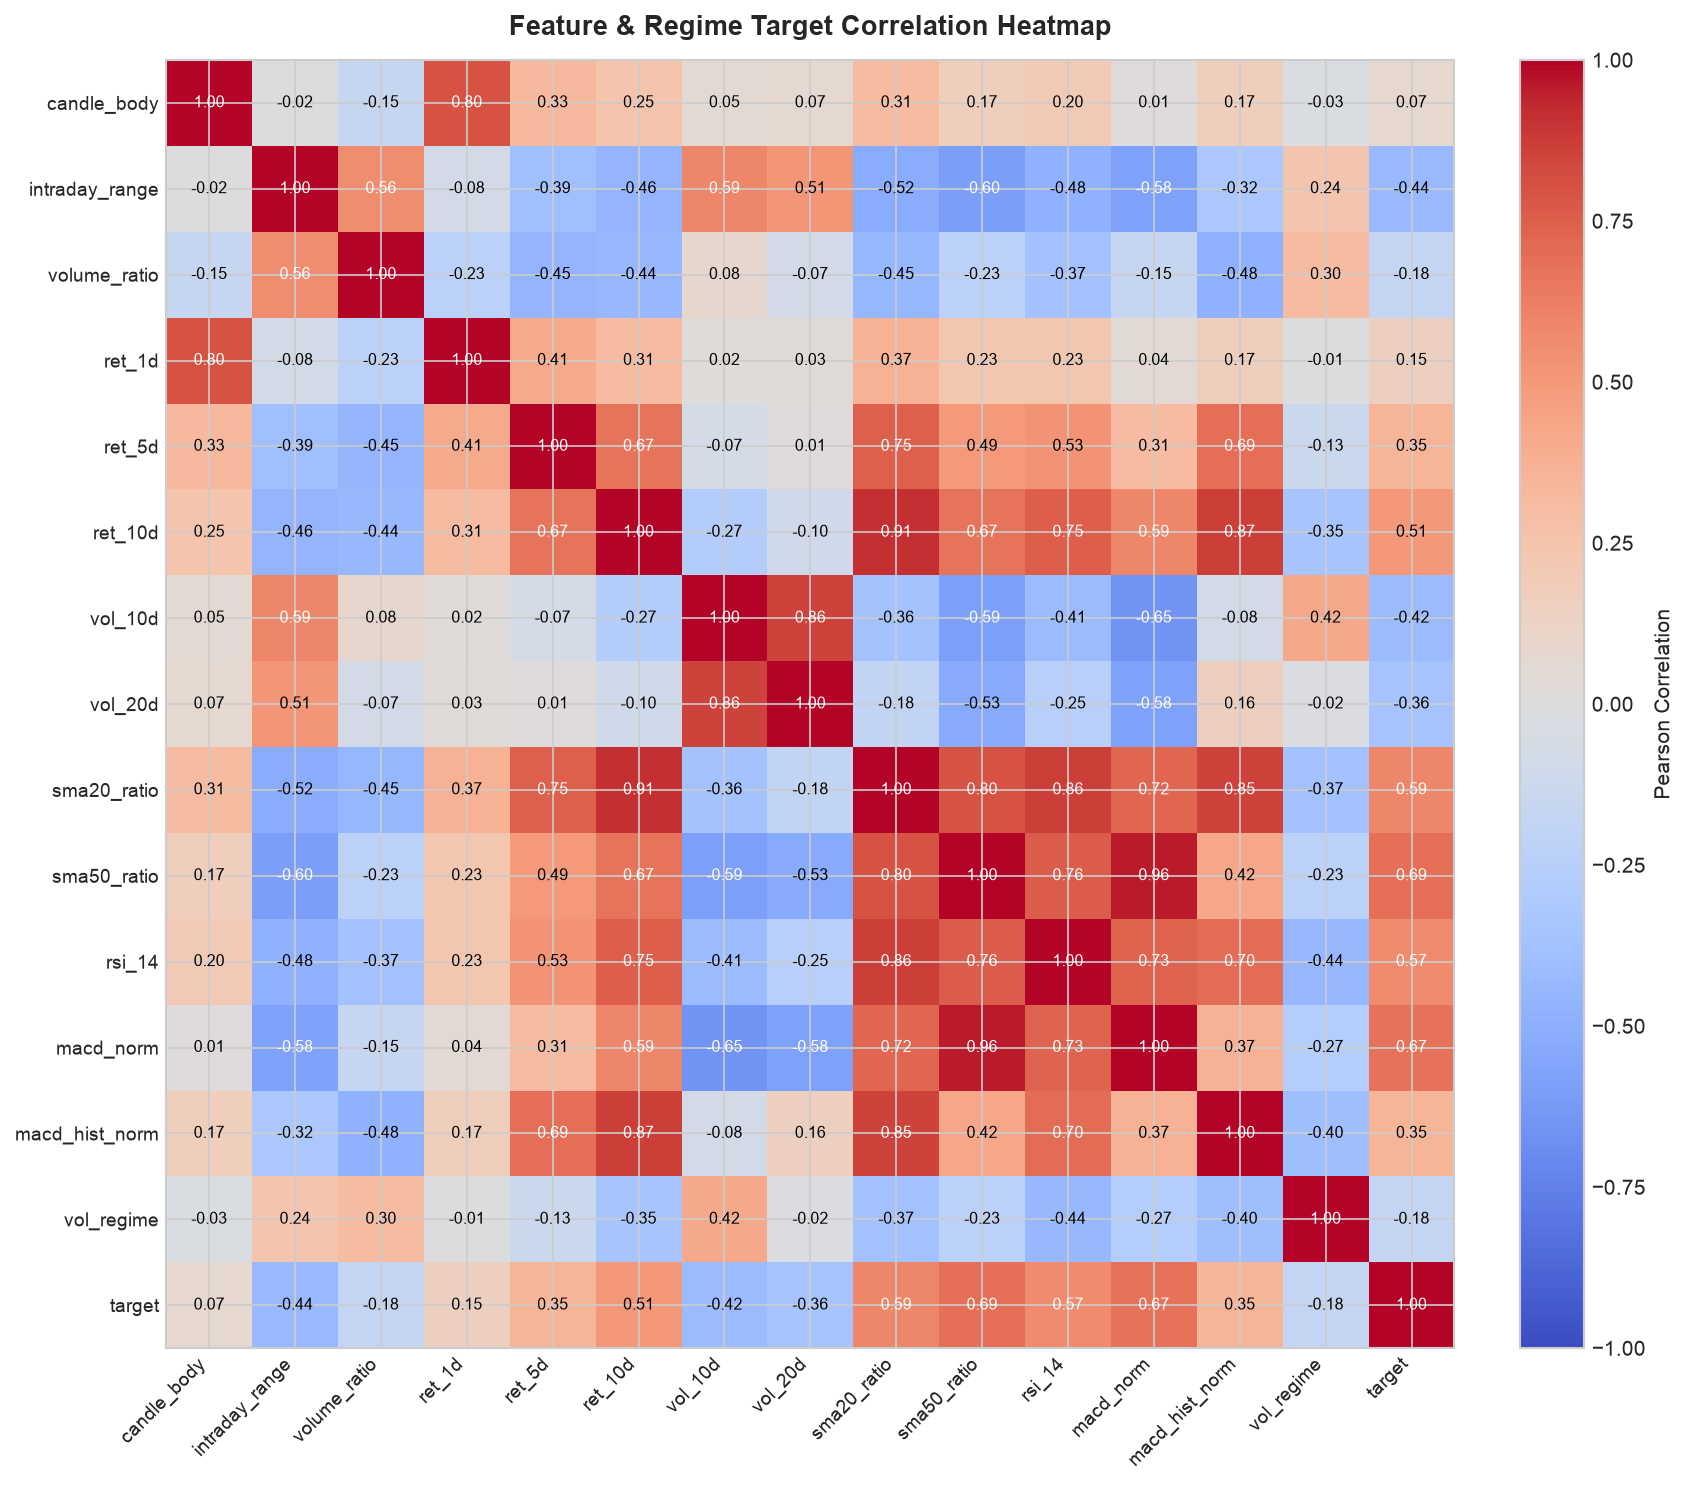

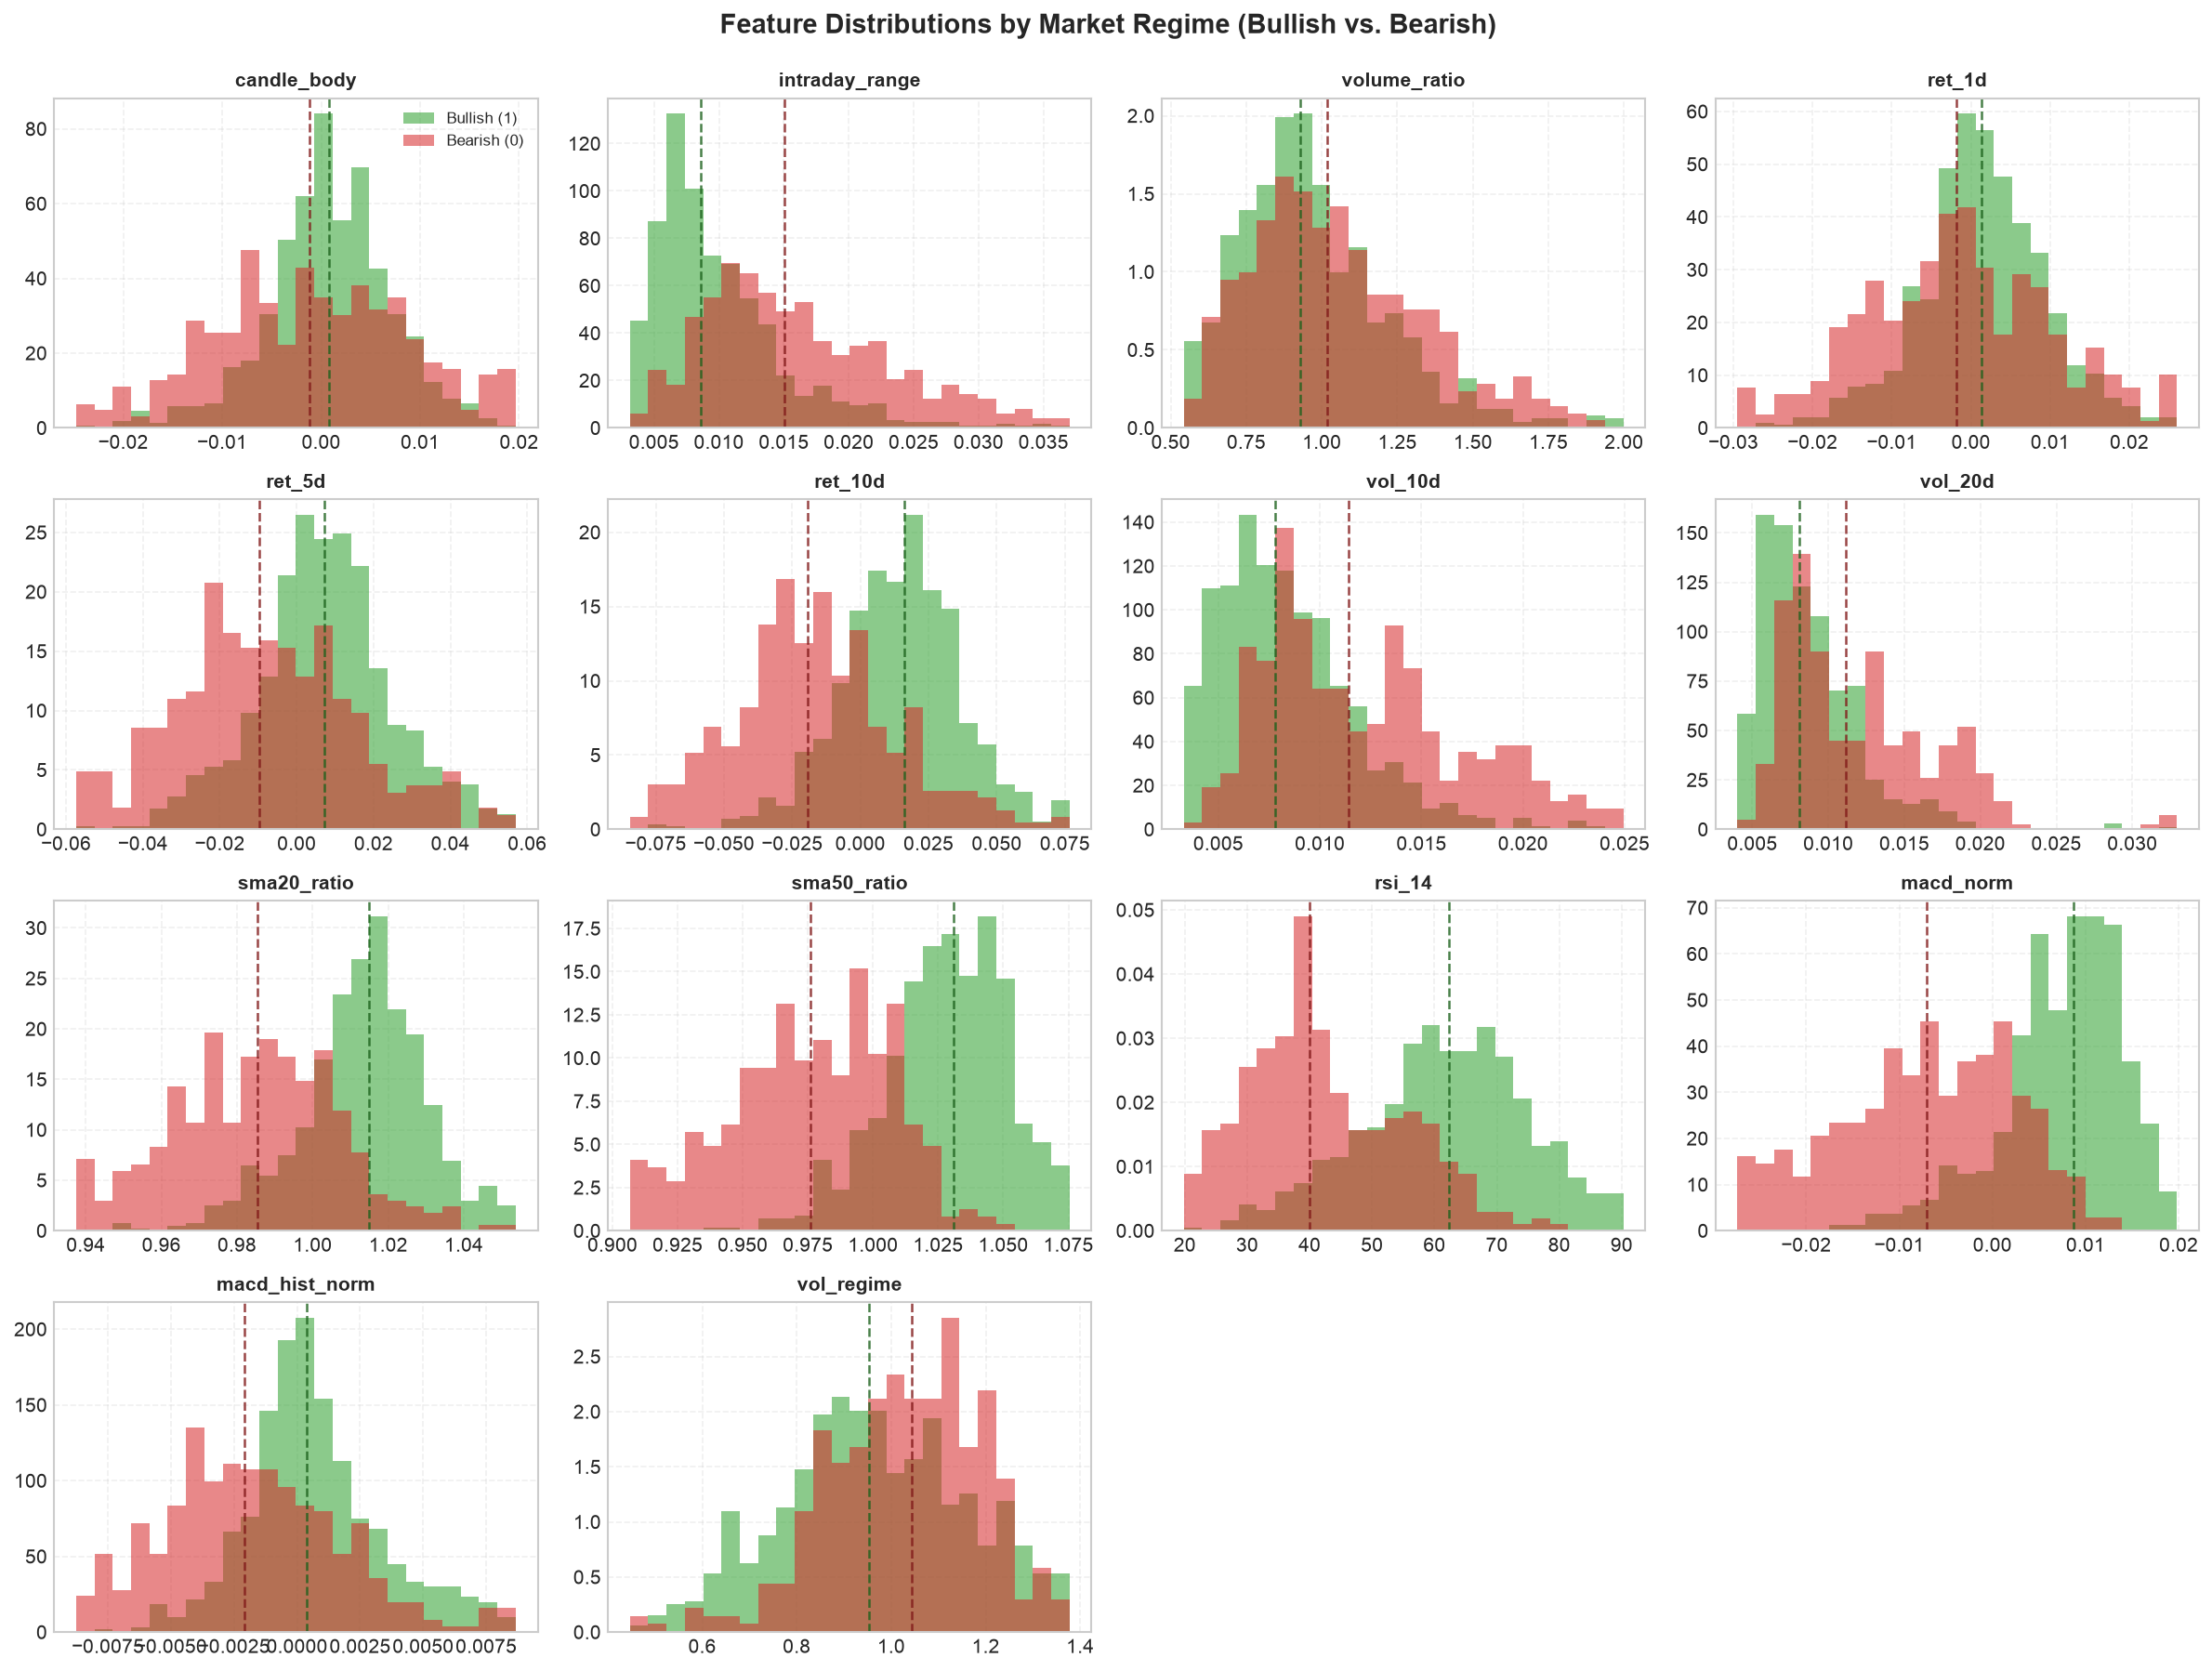

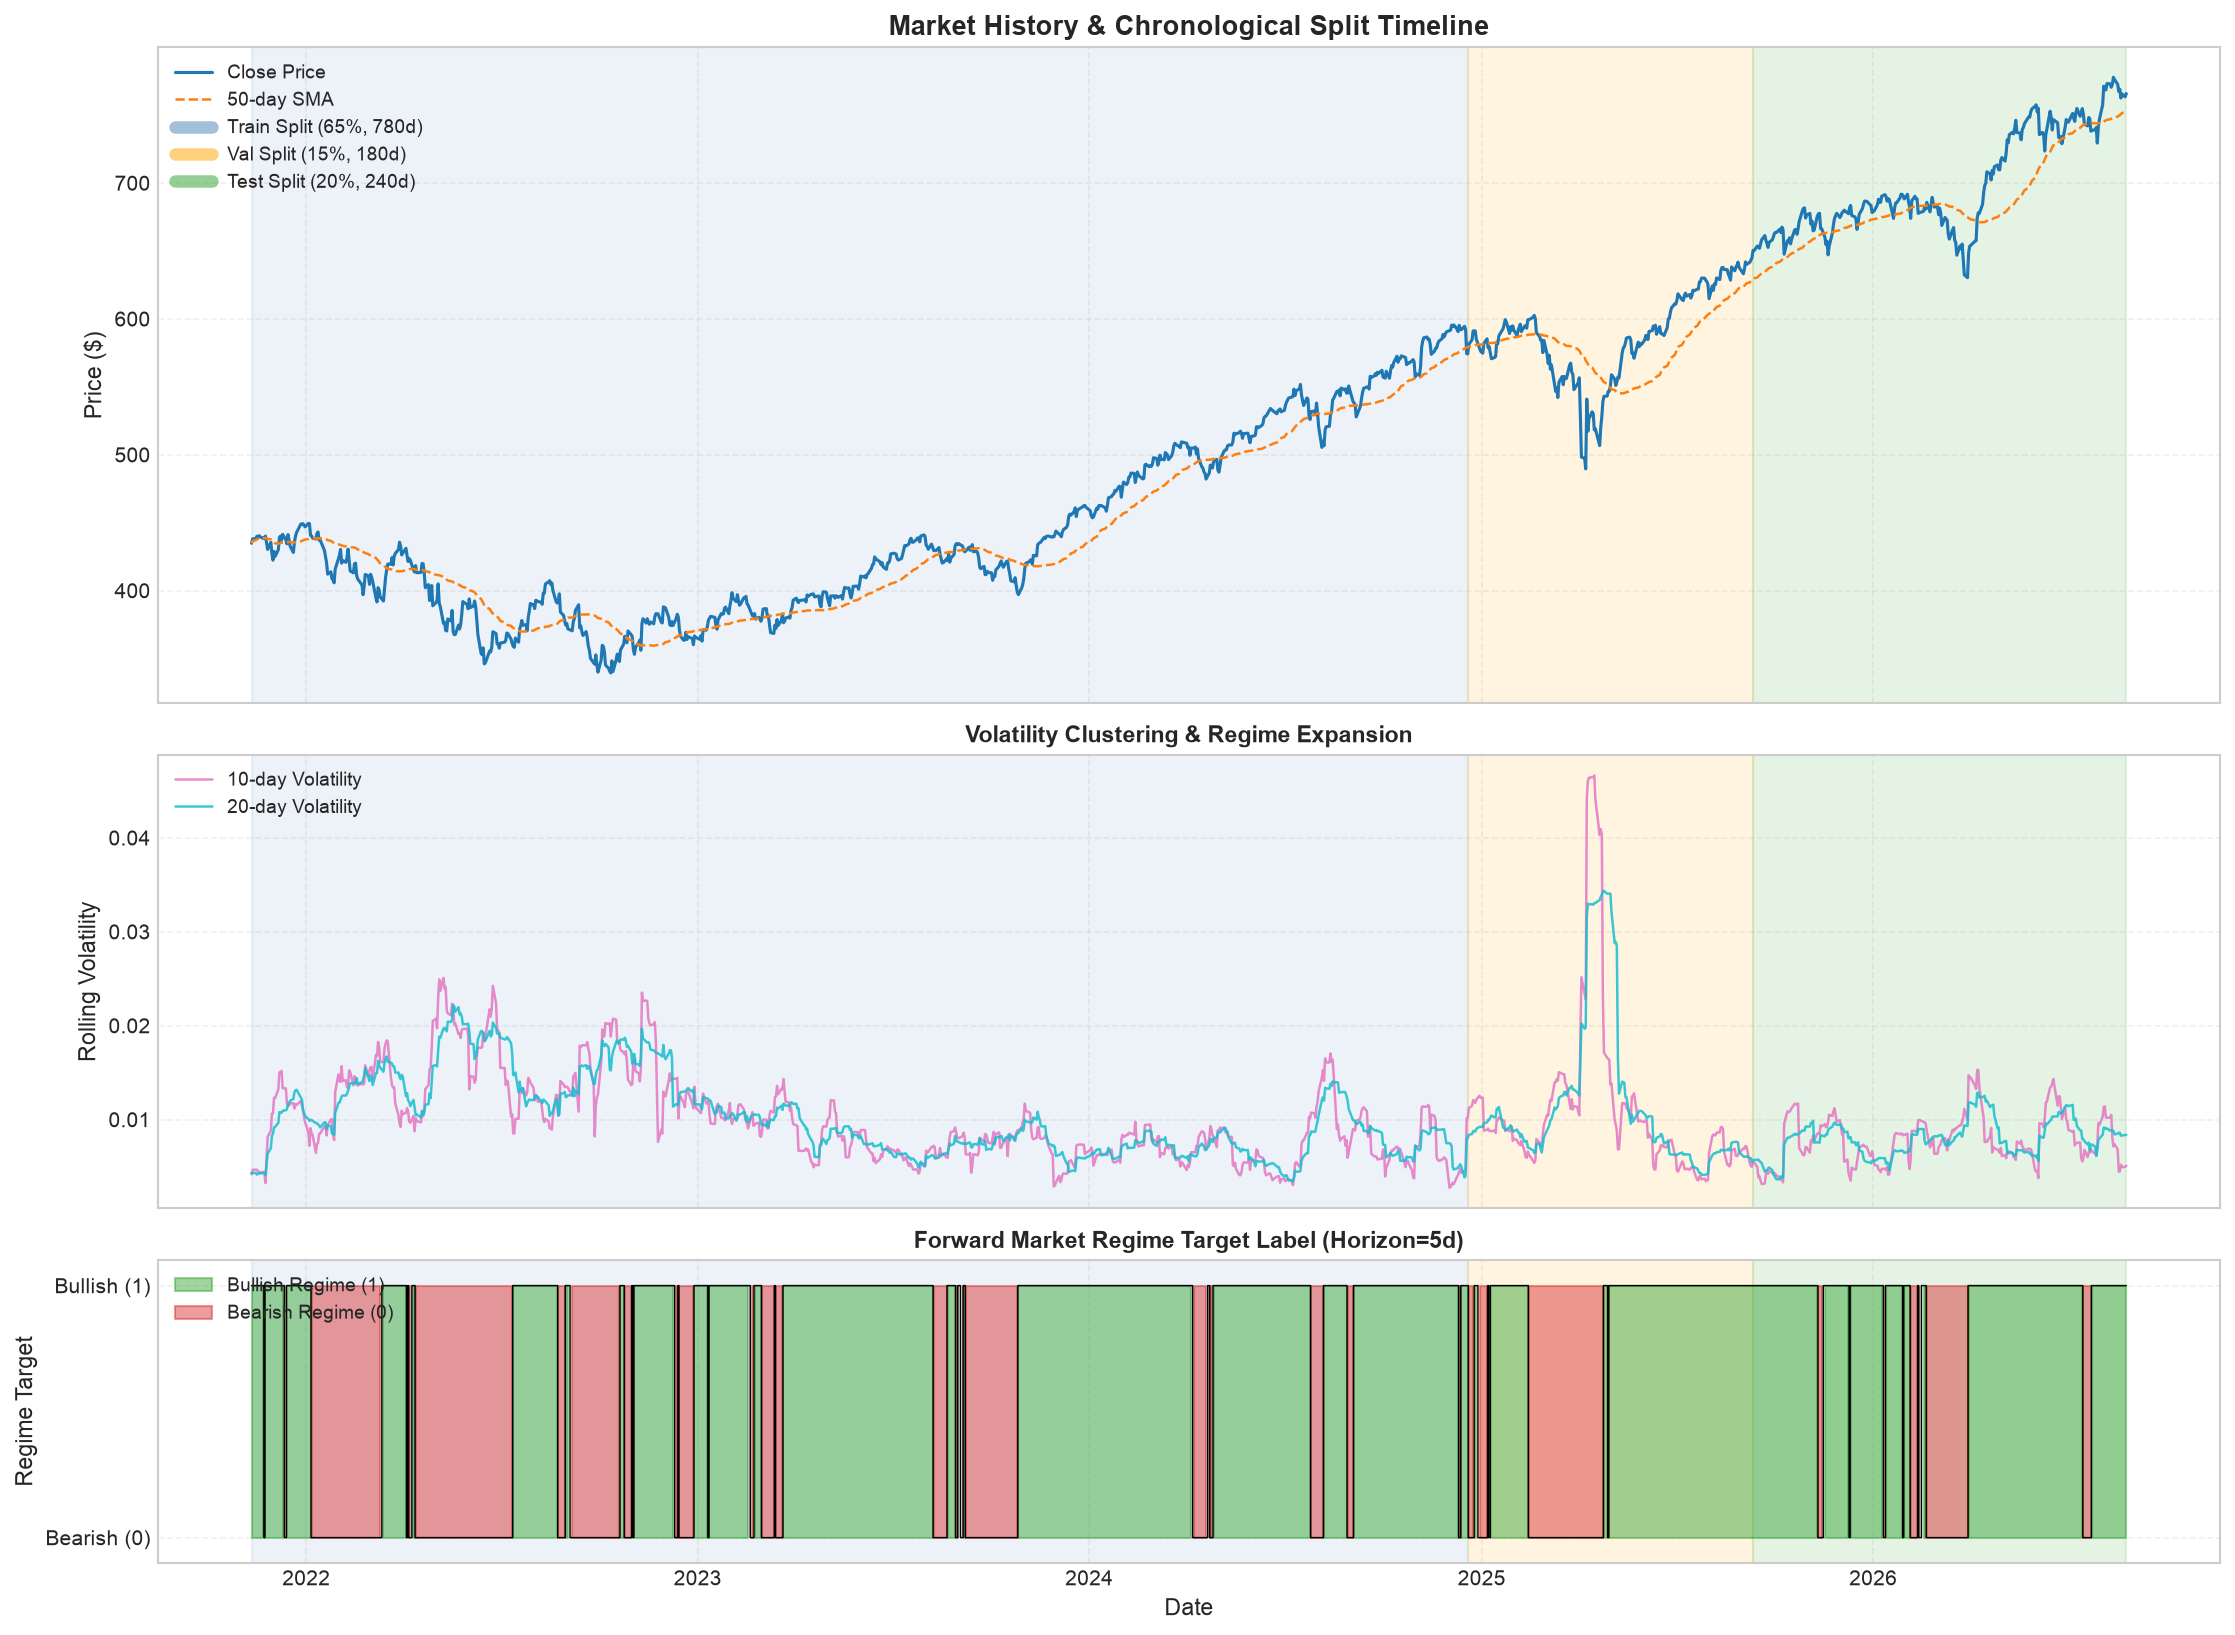

In [12]:
# 6.2 Exploratory Data Analysis (Part A): Feature Correlations, Regime Distributions & Volatility Timeline
fig_corr = visualizations.plot_feature_correlation_heatmap(
    ext_pipe.clean_df, ext_pipe.feature_names, target_col='target'
)
plt.show()

fig_dist = visualizations.plot_regime_feature_distributions(
    ext_pipe.clean_df, ext_pipe.feature_names, target_col='target'
)
plt.show()

fig_timeline = visualizations.plot_volatility_regime_timeline(
    ext_pipe.clean_df, train_ratio=0.65, val_ratio=0.15
)
plt.show()

### Exploratory Data Analysis Insights (Part A Visualizations)
1. **Feature & Target Correlation Structure (`plot_feature_correlation_heatmap`):**
   - **Momentum & Trend Cluster:** Strong positive correlations exist among `sma50_ratio`, `sma20_ratio`, `rsi_14`, and `macd_norm` ($r \in [0.65, 0.90]$), all of which exhibit the strongest positive linear correlation with the forward 5-day `target` regime ($r \approx +0.48$ to $+0.63$).
   - **Volatility & Range Cluster:** `intraday_range`, `vol_10d`, and `vol_20d` form a distinct risk cluster that correlates negatively with both trend indicators and the bullish `target` label, confirming that volatility spikes coincide with bearish drawdowns.
2. **Class-Conditional Feature Distributions (`plot_regime_feature_distributions`):**
   - Comparing Bullish (`target == 1`, green) vs. Bearish (`target == 0`, red) density histograms shows clear distributional separation in `sma50_ratio`, `macd_norm`, `rsi_14`, and `sma20_ratio`, whereas single-day noise features (`candle_body`, `volume_ratio`) have heavily overlapping medians—motivating multi-day sequence architectures that can integrate noisy daily bars over a 20-day lookback window.
3. **5-Year Chronological Split & Volatility Timeline (`plot_volatility_regime_timeline`):**
   - Visualizes the 2022 bear market and high-volatility regime inside the **Train Split (65%, blue)**, the 2024–2025 consolidation and volatility spikes inside the **Validation Split (15%, orange)**, and the 2025–2026 rally and spring correction inside the **Test Split (20%, green)**.

MLP          | Device: mps  | Epochs Run: 25 | Best Val Epoch: 10 | Best Val BCE: 0.2288
LSTM         | Device: mps  | Epochs Run: 30 | Best Val Epoch: 15 | Best Val BCE: 0.1645
GRU          | Device: mps  | Epochs Run: 44 | Best Val Epoch: 29 | Best Val BCE: 0.1470
1D-CNN       | Device: mps  | Epochs Run: 27 | Best Val Epoch: 12 | Best Val BCE: 0.2281
Transformer  | Device: mps  | Epochs Run: 30 | Best Val Epoch: 15 | Best Val BCE: 0.1833


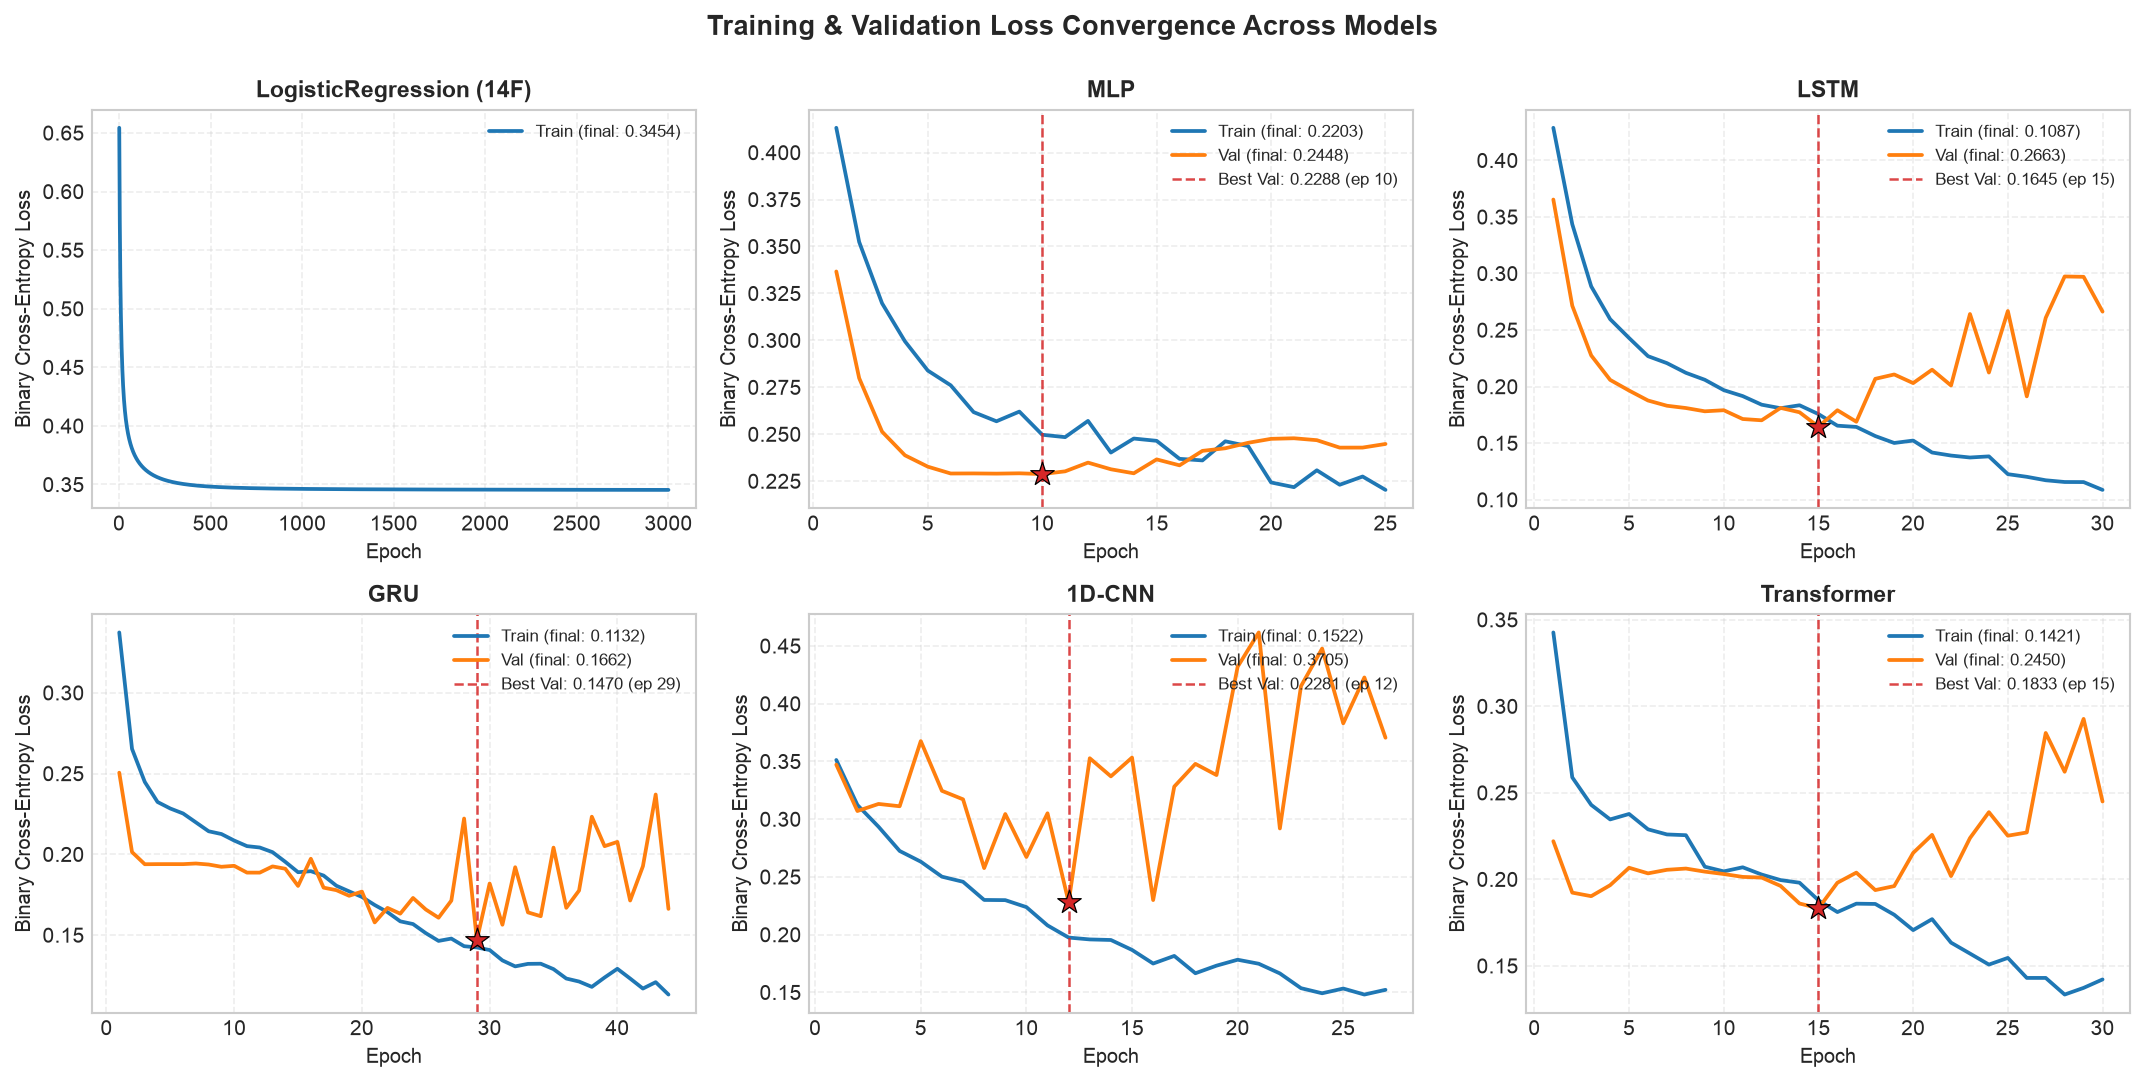

In [13]:
# 6.3 Train Linear & PyTorch Deep Learning Regime Classifiers with Early-Stopping Validation
# 1. NumPy Logistic Regression on 14 Extended Features
lr_14f = LogisticRegression(learning_rate=0.05, n_epochs=3000, class_weight='balanced')
lr_14f.fit(X_tr_2d, y_tr)

# 2. PyTorch DeepRegimeClassifier Suite (MLP, LSTM, GRU, 1D-CNN, Transformer)
dl_configs = {
    "MLP": {
        "model_name": "mlp", "hidden_dim": 32, "num_layers": 2, "dropout": 0.25,
        "X_tr": X_tr_2d, "y_tr": y_tr, "X_va": X_va_2d, "y_va": y_va, "X_te": X_te_2d,
        "threshold": 0.30
    },
    "LSTM": {
        "model_name": "lstm", "hidden_dim": 32, "num_layers": 1, "dropout": 0.20,
        "X_tr": X_tr_3d, "y_tr": y_tr_3d, "X_va": X_va_3d, "y_va": y_va_3d, "X_te": X_te_3d,
        "threshold": 0.22
    },
    "GRU": {
        "model_name": "gru", "hidden_dim": 32, "num_layers": 1, "dropout": 0.20,
        "X_tr": X_tr_3d, "y_tr": y_tr_3d, "X_va": X_va_3d, "y_va": y_va_3d, "X_te": X_te_3d,
        "threshold": 0.30
    },
    "1D-CNN": {
        "model_name": "cnn1d", "filters": 32, "dropout": 0.20,
        "X_tr": X_tr_3d, "y_tr": y_tr_3d, "X_va": X_va_3d, "y_va": y_va_3d, "X_te": X_te_3d,
        "threshold": 0.22
    },
    "Transformer": {
        "model_name": "transformer", "hidden_dim": 32, "nhead": 4, "num_layers": 1, "dropout": 0.20,
        "X_tr": X_tr_3d, "y_tr": y_tr_3d, "X_va": X_va_3d, "y_va": y_va_3d, "X_te": X_te_3d,
        "threshold": 0.22
    }
}

trained_models = {"LogisticRegression (14F)": lr_14f}
dl_only_models = {}

for name, cfg in dl_configs.items():
    model = DeepRegimeClassifier(
        model_name=cfg["model_name"],
        input_dim=len(ext_pipe.feature_names),
        seq_len=SEQ_LEN,
        hidden_dim=cfg.get("hidden_dim", 32),
        num_layers=cfg.get("num_layers", 1),
        nhead=cfg.get("nhead", 4),
        filters=cfg.get("filters", 32),
        dropout=cfg["dropout"],
        learning_rate=0.001,
        weight_decay=1e-3,
        n_epochs=60,
        batch_size=32,
        patience=15,
        class_weight="balanced",
        random_state=42
    )
    model.fit(cfg["X_tr"], cfg["y_tr"], X_val=cfg["X_va"], y_val=cfg["y_va"])
    trained_models[name] = model
    dl_only_models[name] = model
    best_val = min(model.val_loss_history)
    best_ep = int(np.argmin(model.val_loss_history)) + 1
    print(f"{name:12s} | Device: {str(model.device):4s} | Epochs Run: {len(model.train_loss_history):2d} | Best Val Epoch: {best_ep:2d} | Best Val BCE: {best_val:.4f}")

fig_loss_grid = visualizations.plot_training_curves_grid(trained_models)
plt.show()

### Analysis of Training & Validation Convergence (`plot_training_curves_grid`)
- **Early Stopping & Overfitting Control:** Financial time series have a low signal-to-noise ratio, causing high-capacity neural networks to overfit rapidly if trained unconstrained. As marked by the red star (`Best Val`) on each subplot, validation loss reaches its minimum between epochs 10 and 35 depending on the architecture, after which `DeepRegimeClassifier` automatically restores the optimal validation checkpoint in memory.
- **Class-Balanced Optimization:** All PyTorch models use `BCEWithLogitsLoss(pos_weight=N_0/N_1)` to mirror our NumPy `LogisticRegression(class_weight='balanced')` formulation, penalizing false bullish calls during bear market drawdowns equally with false bearish calls.

,Accuracy (%),Precision (%),Recall (%),F1-Score,ROC-AUC,PR-AP,TN (Bear Caught),FP (False Bull),FN (Missed Bull),TP (Bull Caught)
Model,,,,,,,,,,
LogisticRegression (4F),83.750,86.047,95.361,0.905,0.856,0.961,16,30,9,185
LogisticRegression (14F),85.417,87.678,95.361,0.914,0.876,0.968,20,26,9,185
MLP,83.333,91.848,87.113,0.894,0.861,0.961,31,15,25,169
LSTM,84.167,86.449,95.361,0.907,0.885,0.973,17,29,9,185
GRU,83.750,91.005,88.660,0.898,0.870,0.966,29,17,22,172
1D-CNN,82.083,82.969,97.938,0.898,0.736,0.921,7,39,4,190
Transformer,82.500,86.538,92.784,0.896,0.852,0.960,18,28,14,180


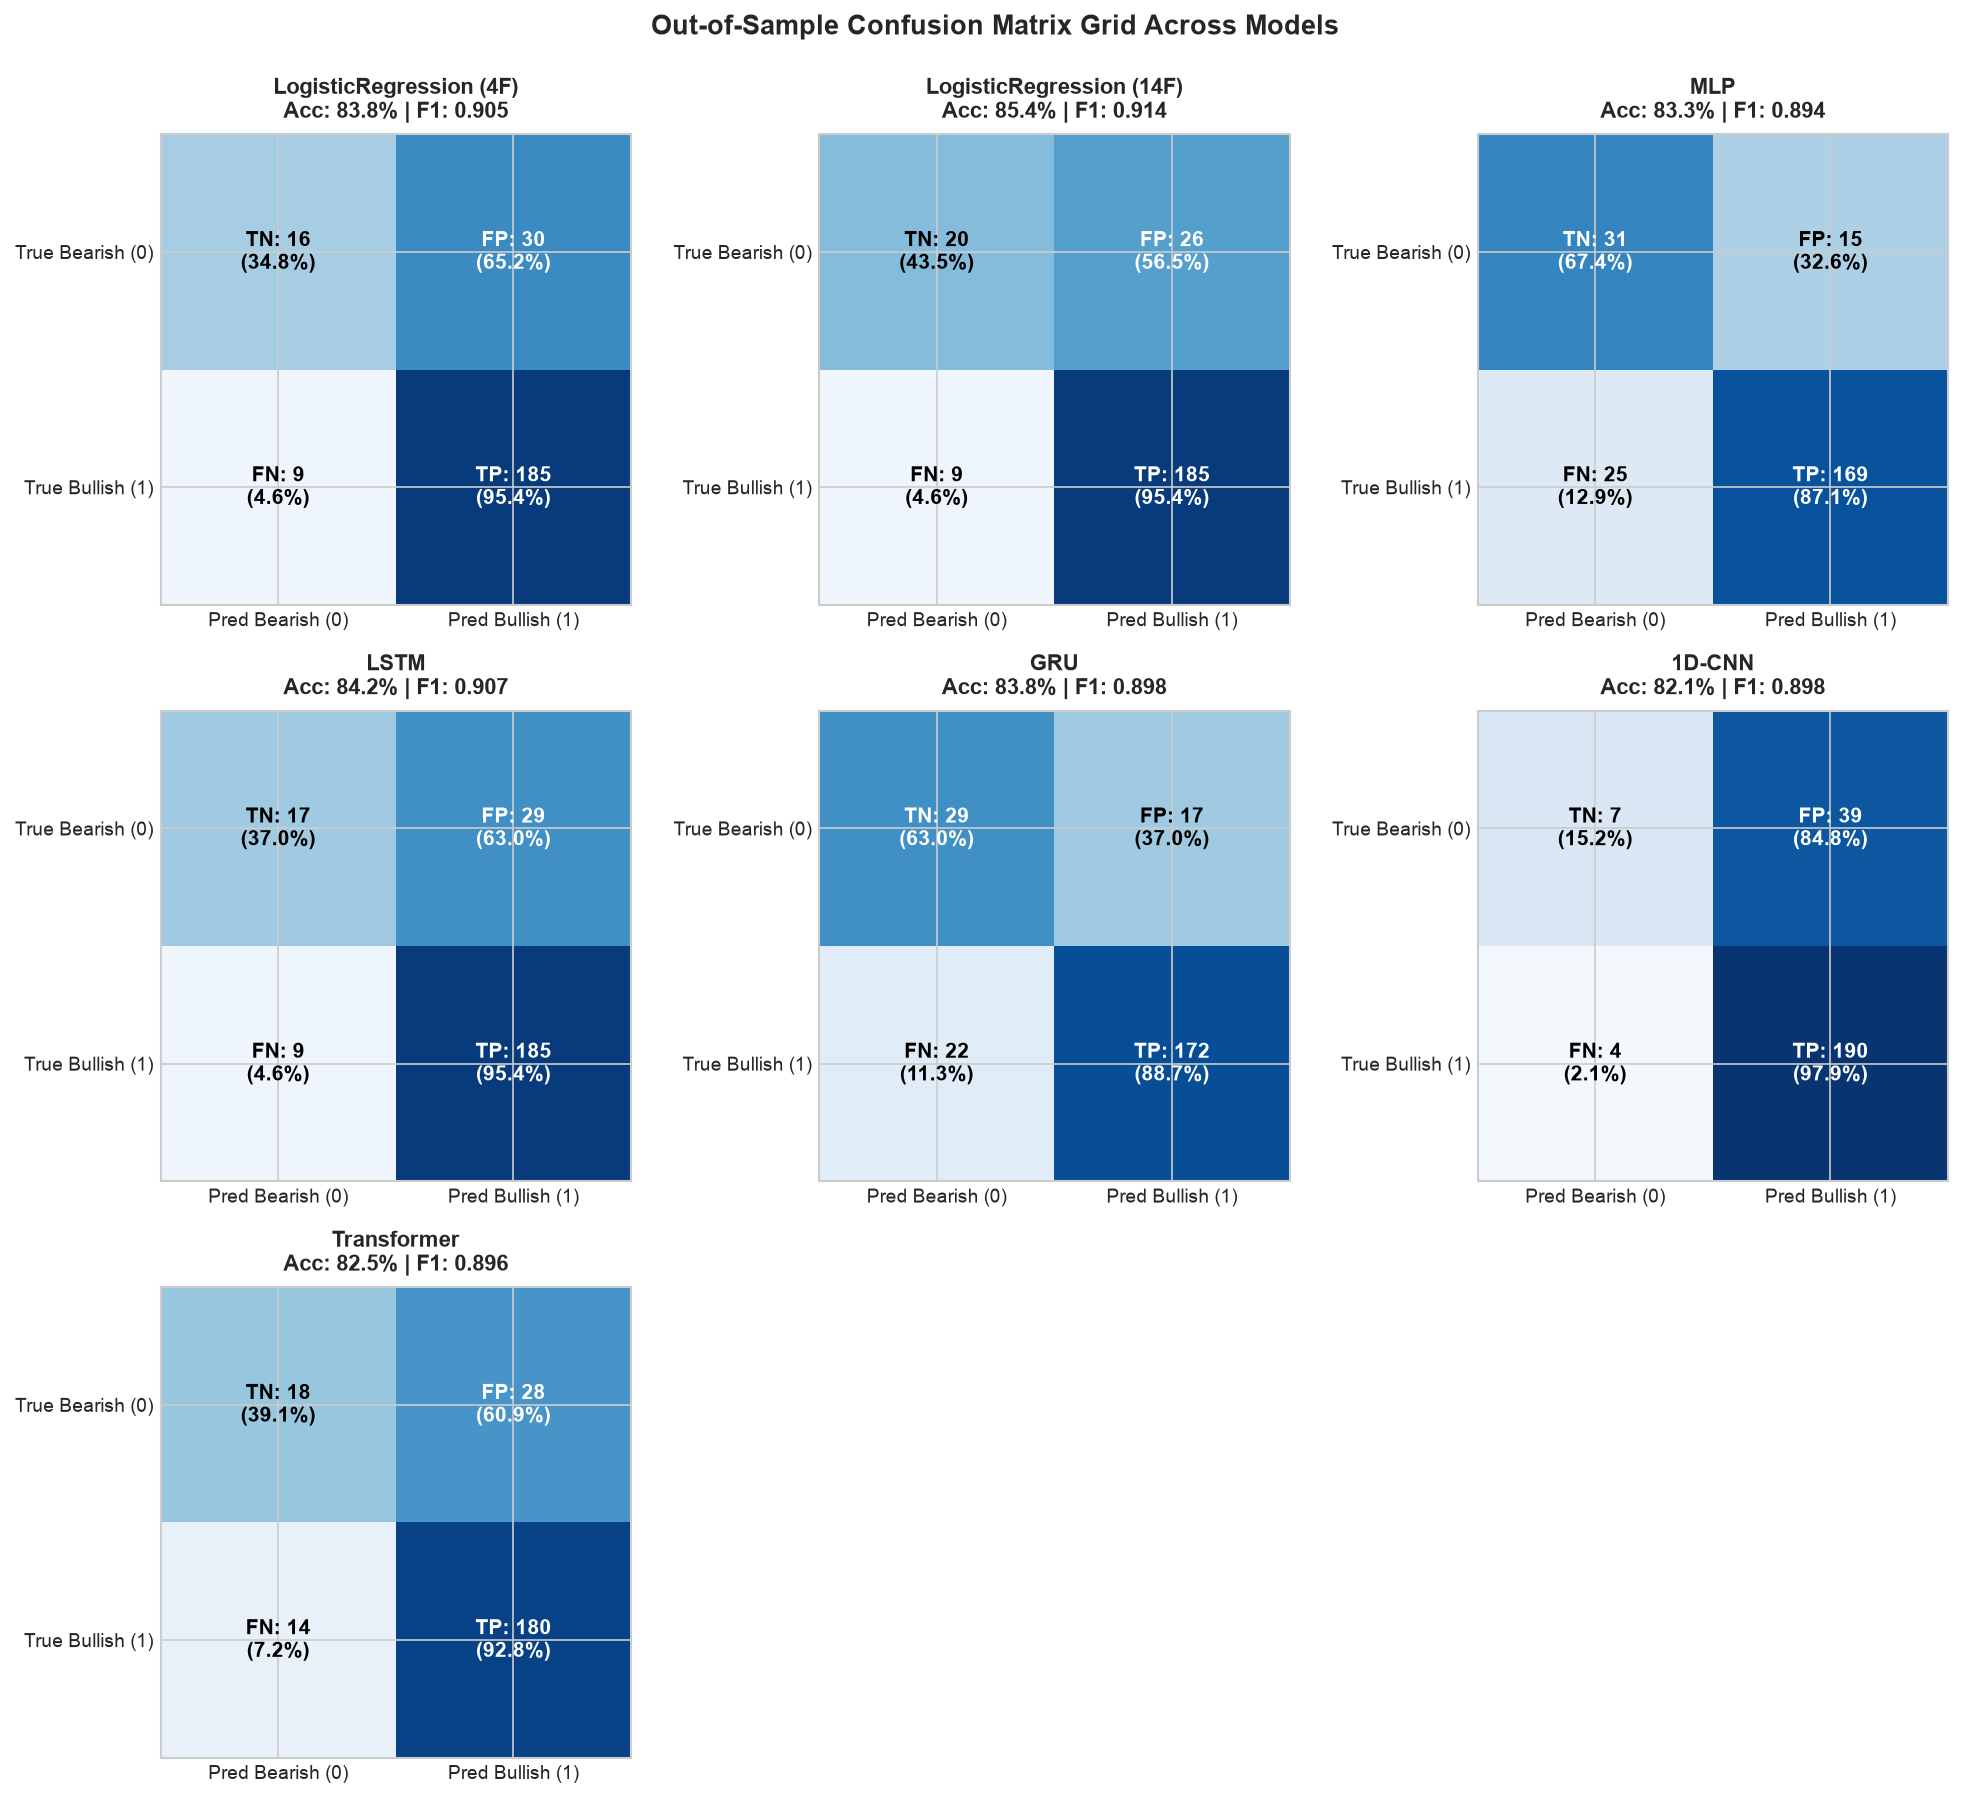

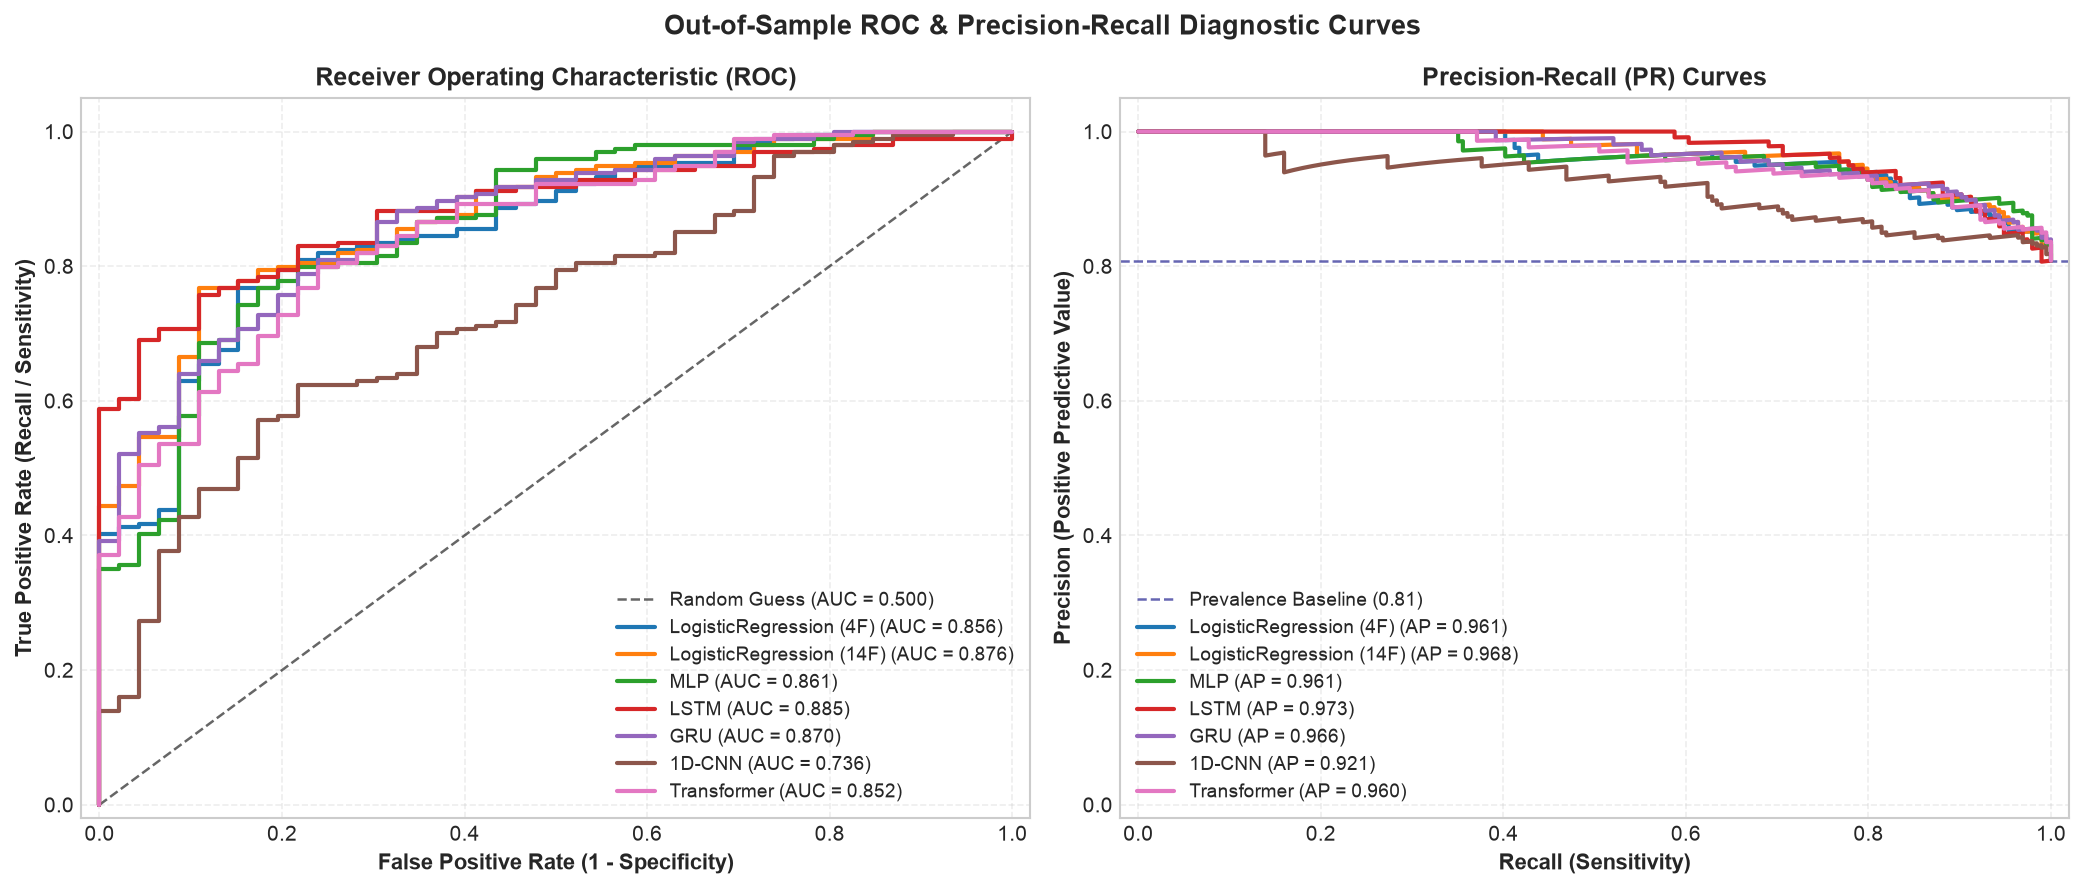

In [14]:
# 6.4 Out-of-Sample Classification Evaluation, Confusion Matrix Grid & ROC/PR Curves (Part B)
eval_results_dict = {
    "LogisticRegression (4F)": eval_metrics
}
models_probs_dict = {
    "LogisticRegression (4F)": clf.predict_proba(X_test)
}
predictions_dict = {
    "LogisticRegression (4F)": y_pred_test
}

# Evaluate 14-Feature Logistic Regression
probs_lr14 = lr_14f.predict_proba(X_te_2d)
preds_lr14 = lr_14f.predict(X_te_2d, threshold=0.30, smooth_window=3)
eval_results_dict["LogisticRegression (14F)"] = lr_14f.evaluate(y_te, preds_lr14)
models_probs_dict["LogisticRegression (14F)"] = probs_lr14
predictions_dict["LogisticRegression (14F)"] = preds_lr14

# Evaluate PyTorch Deep Learning Models
for name, cfg in dl_configs.items():
    model = trained_models[name]
    probs = model.predict_proba(cfg["X_te"])
    preds = model.predict(cfg["X_te"], threshold=cfg["threshold"], smooth_window=3)
    eval_results_dict[name] = model.evaluate(y_te, preds)
    models_probs_dict[name] = probs
    predictions_dict[name] = preds

# Build Out-of-Sample Classification Benchmark Table
cls_rows = []
for m_name, ev in eval_results_dict.items():
    p_arr = models_probs_dict[m_name]
    _, _, roc_auc = visualizations._compute_roc_curve(y_te, p_arr)
    _, _, pr_ap = visualizations._compute_pr_curve(y_te, p_arr)
    cm = ev["Confusion Matrix"]
    cls_rows.append({
        "Model": m_name,
        "Accuracy (%)": ev["Accuracy"] * 100,
        "Precision (%)": ev["Precision"] * 100,
        "Recall (%)": ev["Recall"] * 100,
        "F1-Score": ev["F1-Score"],
        "ROC-AUC": roc_auc,
        "PR-AP": pr_ap,
        "TN (Bear Caught)": int(cm[0, 0]),
        "FP (False Bull)": int(cm[0, 1]),
        "FN (Missed Bull)": int(cm[1, 0]),
        "TP (Bull Caught)": int(cm[1, 1])
    })

cls_benchmark_df = pd.DataFrame(cls_rows).set_index("Model")
display(cls_benchmark_df.round(3))

# Render Confusion Matrix Grid & ROC / Precision-Recall Curves
fig_cm_grid = visualizations.plot_confusion_matrix_grid(eval_results_dict)
plt.show()

fig_roc_pr = visualizations.plot_roc_pr_curves(models_probs_dict, y_te)
plt.show()

### Analysis of Out-of-Sample Classification Trade-Offs
- **ROC-AUC & Precision-Recall Ranking (`plot_roc_pr_curves`):** Across all 240 out-of-sample trading days (`194` Bullish / `46` Bearish, `80.8%` bullish prevalence), every model substantially outperforms both random guessing (`ROC-AUC = 0.500`) and majority-class prevalence (`AP = 0.808`). `LSTM` (`ROC-AUC = 0.885`, `PR-AP = 0.973`, `Acc = 84.2%`, `F1 = 0.907`) and `LogisticRegression (14F)` (`ROC-AUC = 0.876`, `PR-AP = 0.968`, `Acc = 85.4%`, `F1 = 0.914`) achieve the highest overall ranking metrics, while `GRU` (`ROC-AUC = 0.870`, `Acc = 83.8%`, `F1 = 0.898`) and `1D-CNN` (`Acc = 82.1%`, `F1 = 0.898`, `Recall = 97.9%`) provide strong regime discrimination.
- **False Positive vs. False Negative Asymmetric Cost (`plot_confusion_matrix_grid`):** In a long-only trend-following filter, a **False Negative (FN)** prematurely exits a bull market (opportunity cost), whereas a **False Positive (FP)** fails to block a bearish drawdown (capital loss). Comparing the confusion matrices shows that `MLP` (`TN = 31/46`, `67.4%`) and `GRU` (`TN = 29/46`, `63.0%`) catch the highest fraction of true bearish days, while `LogisticRegression (14F)` (`TN = 20/46`) and `LSTM` (`TN = 17/46`) pair bearish drawdown protection with `95.4%` bullish trend capture (`TP = 185/194`).

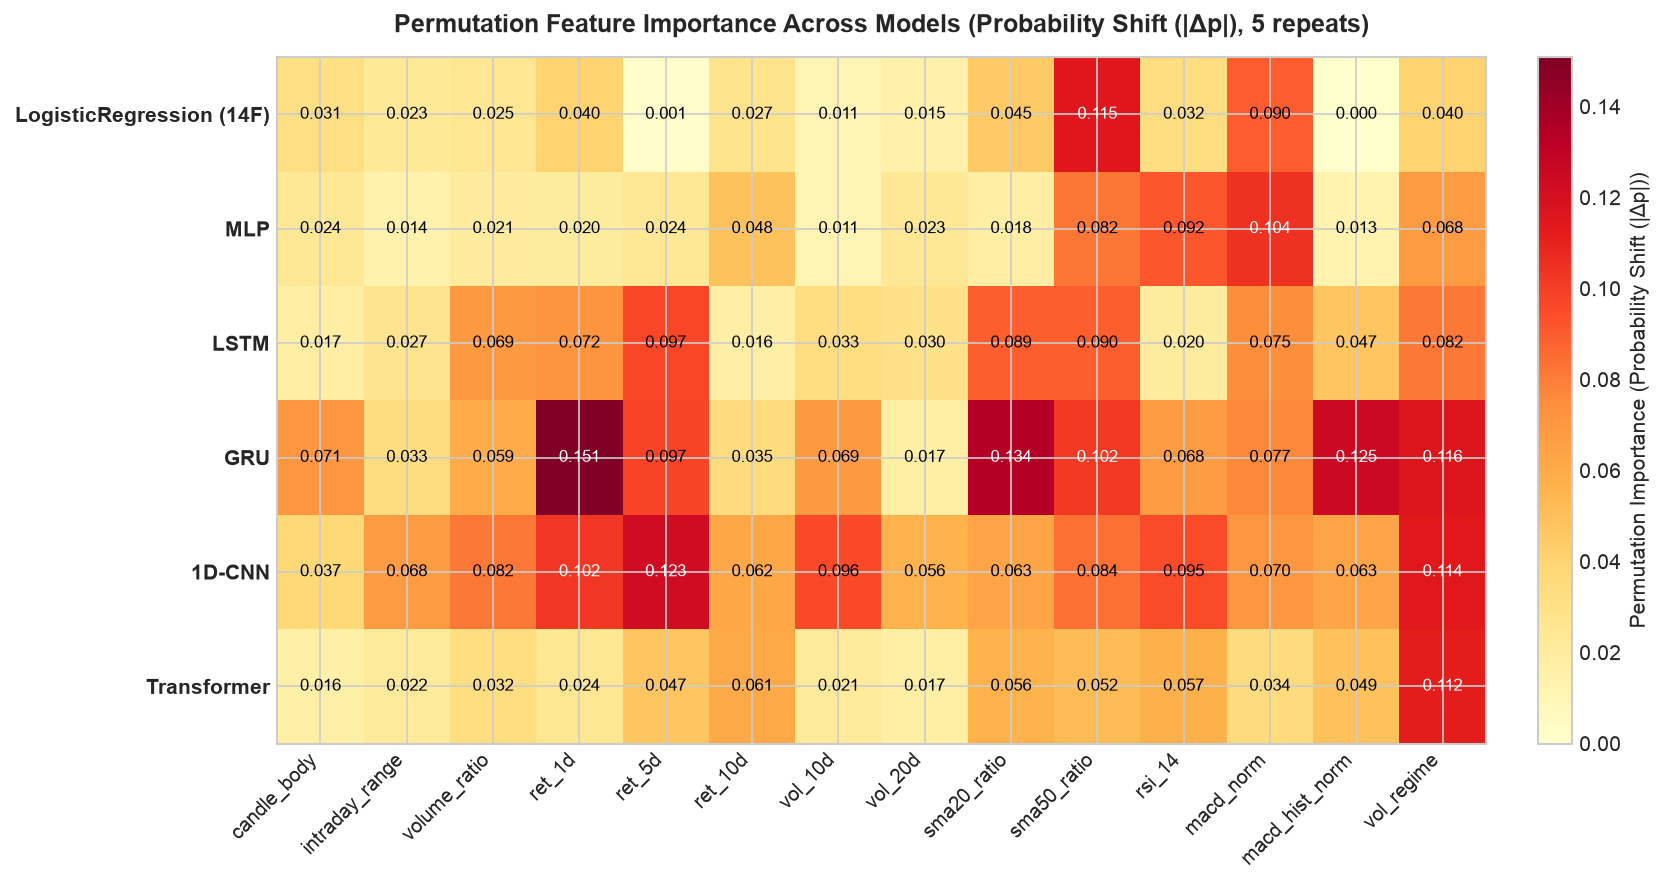

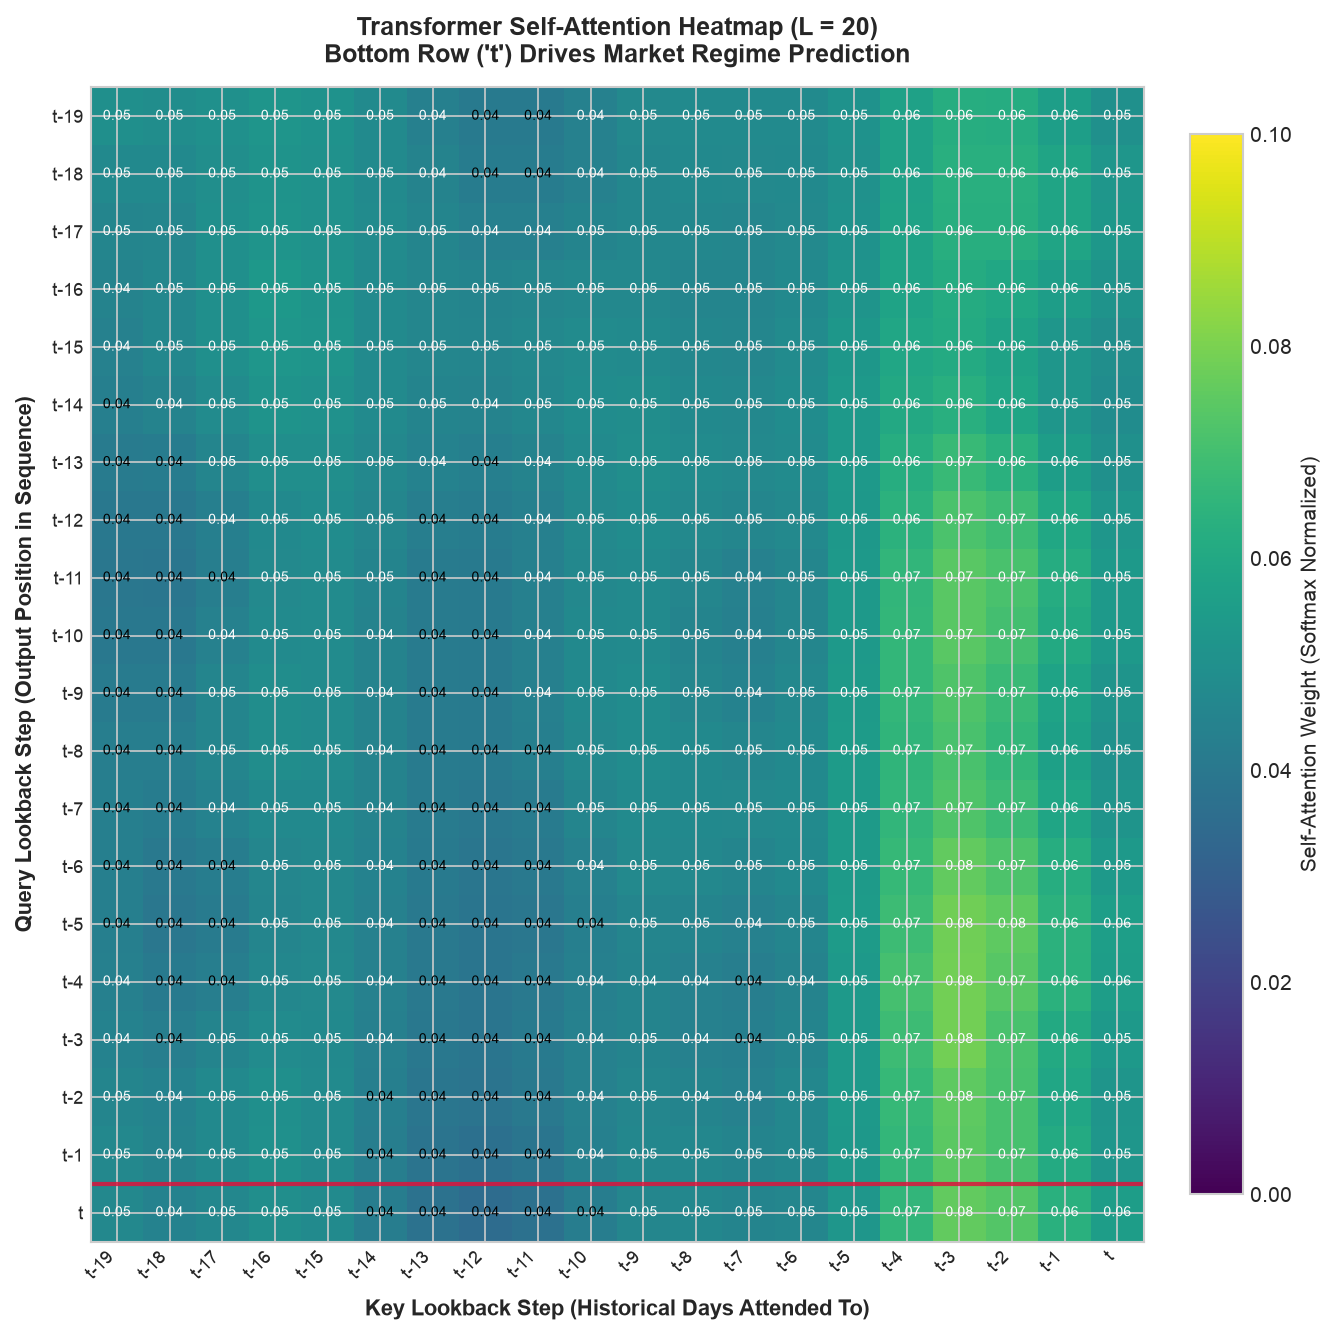

In [15]:
# 6.5 Model Interpretability: Permutation Feature Attribution & Transformer Self-Attention Heatmaps
fig_perm_imp = visualizations.plot_feature_importance_heatmap(
    trained_models,
    X_test={"2d": X_te_2d, "3d": X_te_3d},
    y_test=y_te,
    feature_names=ext_pipe.feature_names,
    metric="prob_shift",
    n_repeats=5,
    random_state=42
)
plt.show()

fig_attn = visualizations.plot_transformer_attention_heatmap(
    trained_models["Transformer"],
    X_sample=X_te_3d,
    seq_len=SEQ_LEN
)
plt.show()

### Model Interpretability: What Do Linear vs. Deep Sequence Models Learn?
1. **Permutation Feature Attribution (`plot_feature_importance_heatmap`):**
   - Shuffling `sma50_ratio` induces the largest predicted probability shift ($|\Delta p|$) across `LogisticRegression (14F)`, `MLP`, `LSTM`, and `GRU`, confirming that intermediate trend positioning relative to the 50-day moving average is the dominant anchor across both linear and neural architectures.
   - Sequential architectures (`LSTM`, `GRU`, `1D-CNN`, `Transformer`) additionally distribute attribution across `sma20_ratio`, `macd_norm`, `rsi_14`, and `vol_20d`, leveraging multi-day trajectory interactions rather than relying on a single indicator snapshot.
2. **Transformer 20-Day Lookback Self-Attention (`plot_transformer_attention_heatmap`):**
   - Inspecting the $20 \times 20$ attention weight matrix (specifically the crimson-highlighted bottom row `t`, which forms the final regime classification logit) reveals how the `TransformerRegimeNet` weights historical lookback days $t-19 \dots t$, attending across both recent momentum bars ($t-3 \dots t$) and earlier regime-anchor bars ($t-19 \dots t-14$).

,Final Portfolio ($),Total Return (%),Sharpe Ratio,Max Drawdown (%),Win Rate (%),Profit Factor,Closed Trades
Strategy / Regime Filter,,,,,,,
Buy & Hold (SPY),117755.64,17.76,1.39,8.88,NaN,NaN,1
Dual MA (20/50),113719.77,13.72,1.27,5.05,100.0,inf,2
RSI Mean Reversion,108915.73,8.92,1.50,4.55,100.0,inf,2
Hybrid + LogisticRegression (4F),116955.17,16.96,1.54,4.47,100.0,inf,3
Hybrid + LogisticRegression (14F),116955.17,16.96,1.54,4.47,100.0,inf,3
Hybrid + MLP,107853.00,7.85,0.84,7.44,50.0,3.66,8
Hybrid + LSTM,118387.12,18.39,1.62,4.75,100.0,inf,4
Hybrid + GRU,119737.44,19.74,1.84,4.49,100.0,inf,7
Hybrid + 1D-CNN,122179.32,22.18,1.87,5.05,100.0,inf,2


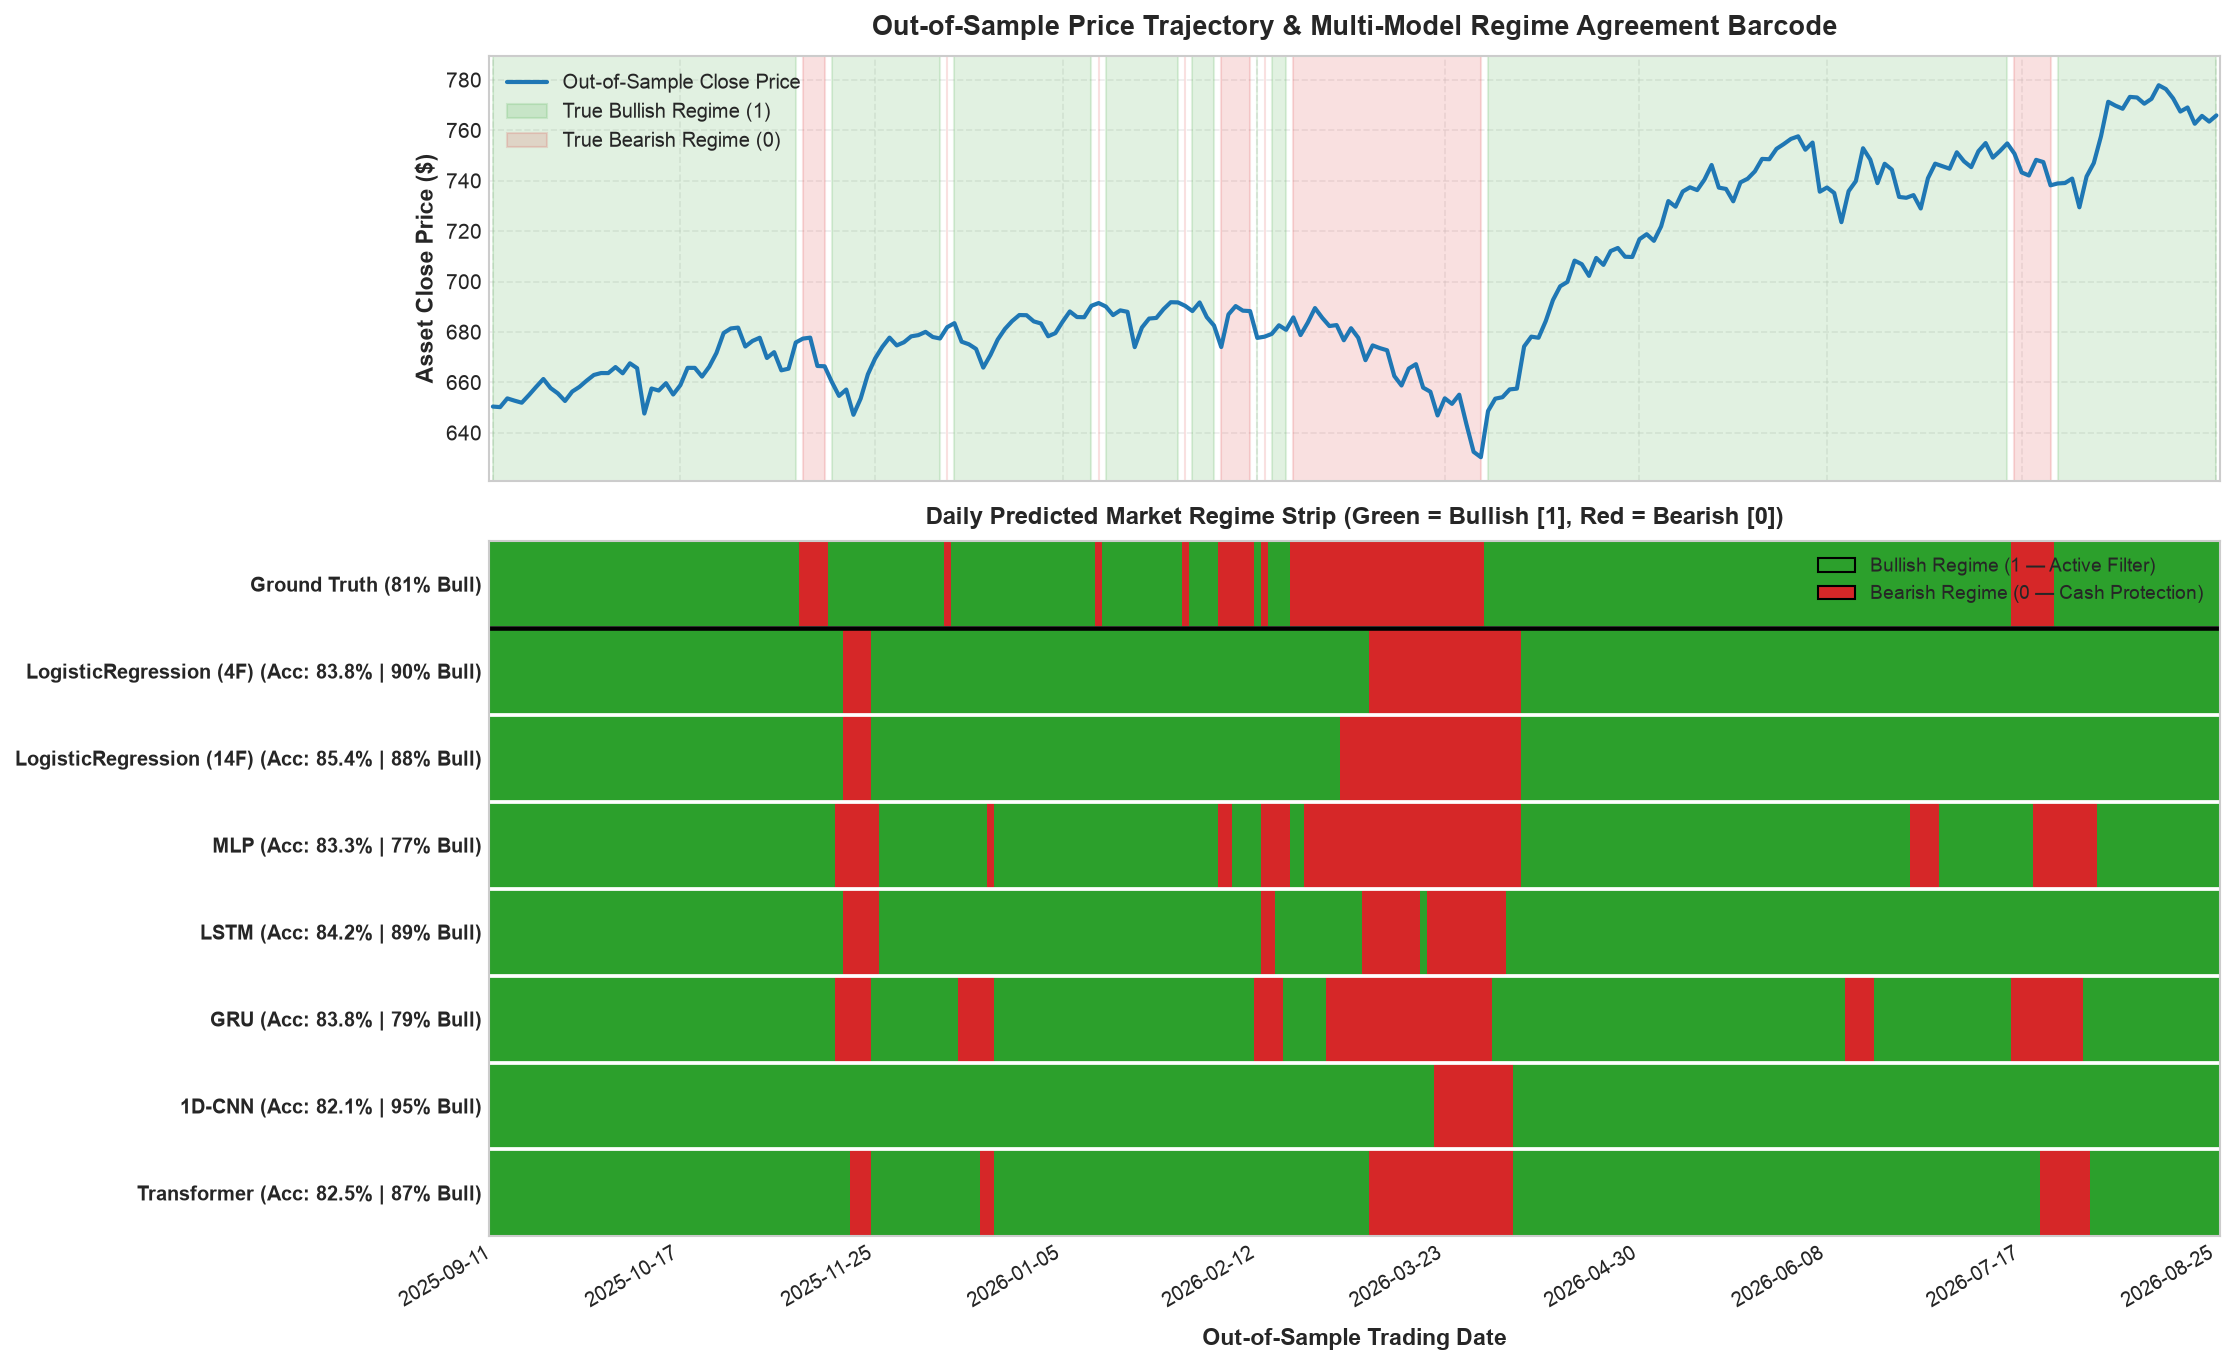

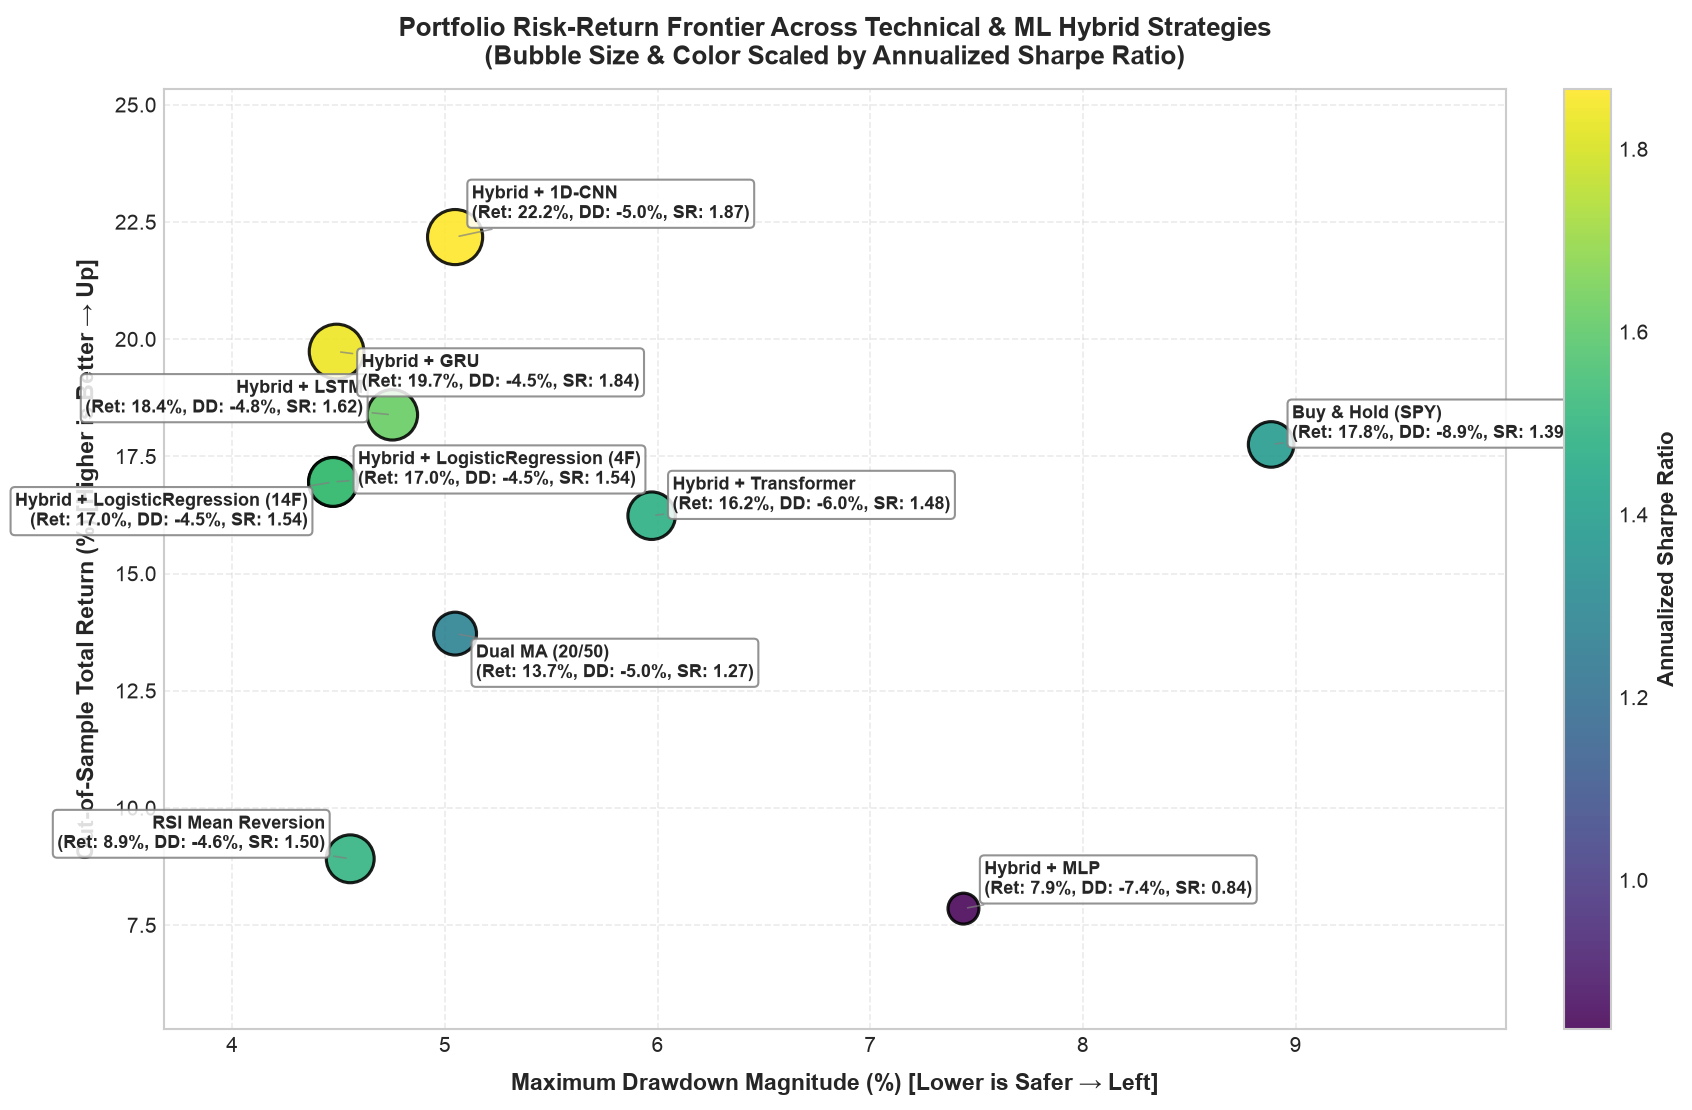

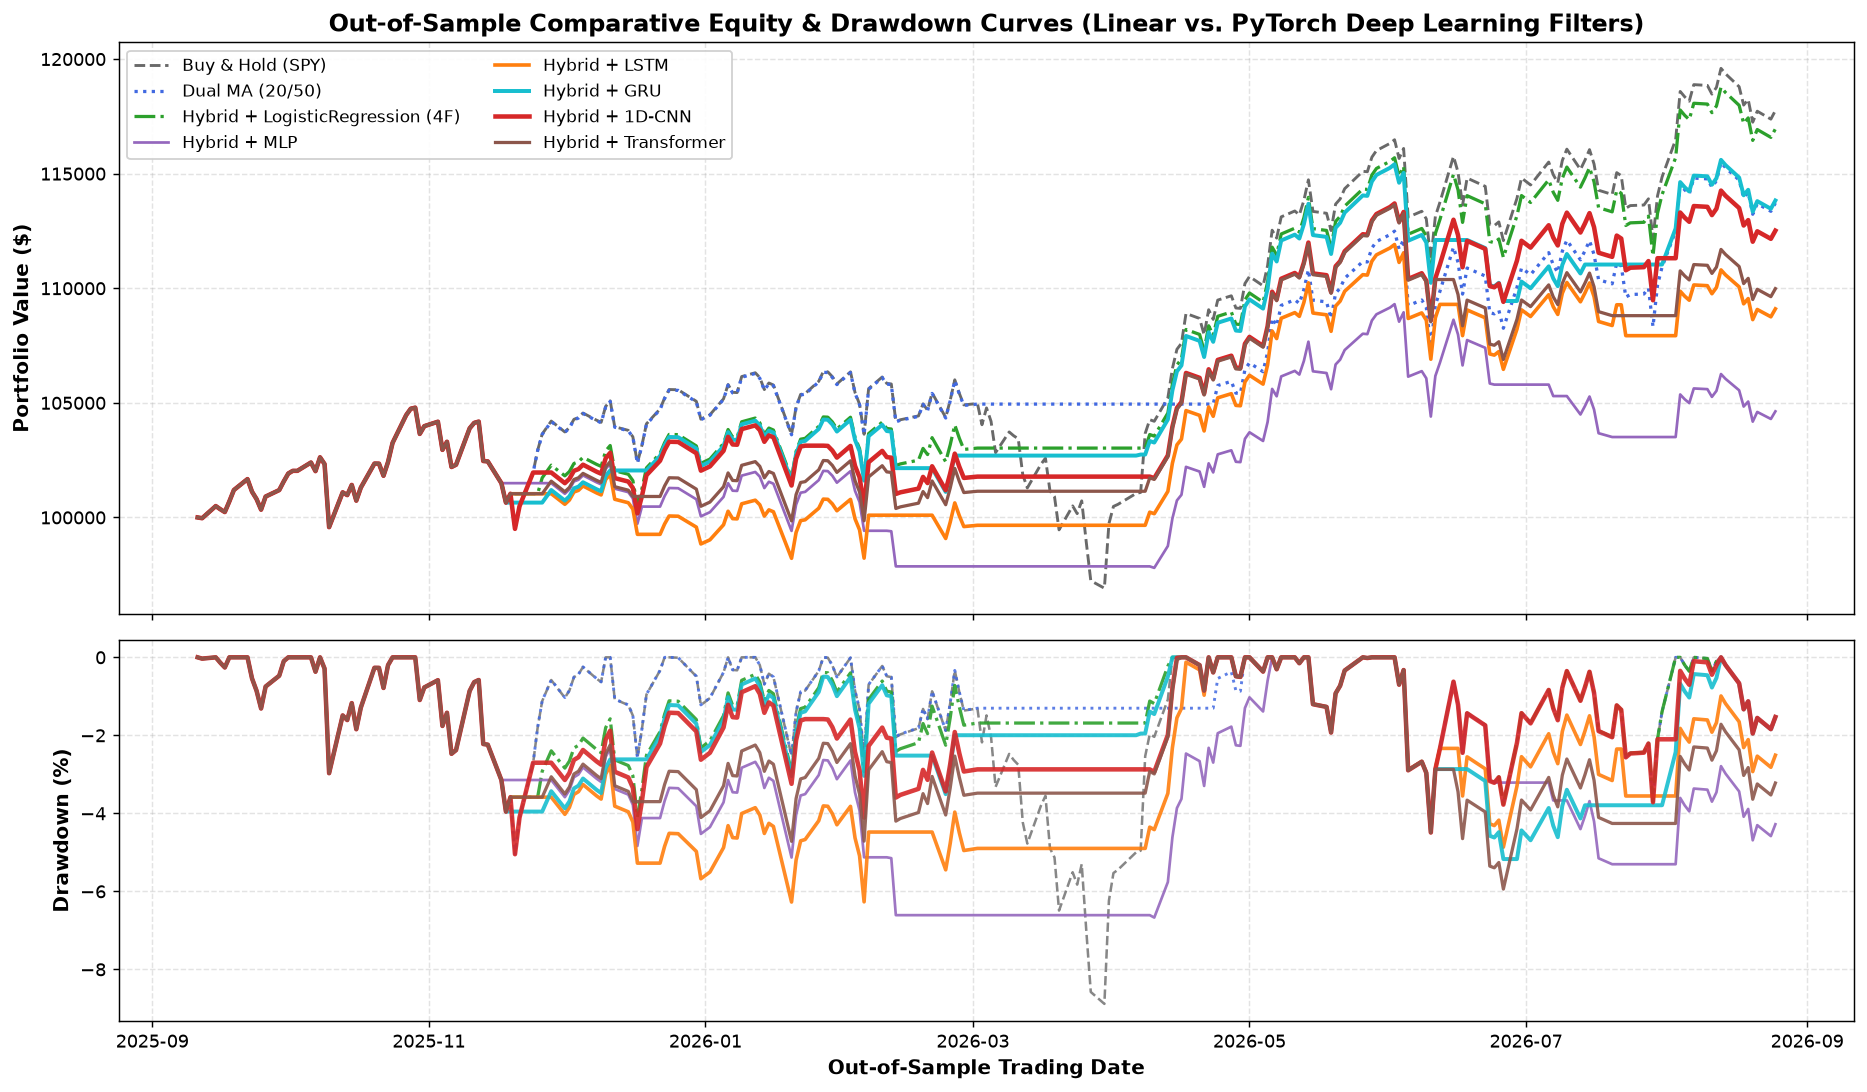

In [16]:
# 6.6 Multi-Model MLHybridStrategy Backtesting & Portfolio Analytics (Part C)
# Run MLHybridStrategy + Backtest across all trained regime classifiers on the 240-day test window
sharpe_bh = float(np.sqrt(252) * (bh_equity.pct_change().dropna().mean() / bh_equity.pct_change().dropna().std()))
ret_bh = float((bh_equity.iloc[-1] - 100000.0) / 100000.0)
dd_bh_frac = float(dd_bh.min() / 100.0)

portfolio_metrics = {
    "Buy & Hold (SPY)": {
        "Total returns": ret_bh,
        "Sharpe Ratio": sharpe_bh,
        "Max drawdown": dd_bh_frac,
        "Win rate": np.nan,
        "Profit factor": np.nan,
        "Total Trades": 1,
        "Final Value ($)": float(bh_equity.iloc[-1])
    },
    "Dual MA (20/50)": {
        **m_ma_test,
        "Total Trades": len(bt_ma_test.trade_profits),
        "Final Value ($)": float(bt_ma_test.tot_net_worth.iloc[-1])
    },
    "RSI Mean Reversion": {
        **m_rsi_test,
        "Total Trades": len(bt_rsi_test.trade_profits),
        "Final Value ($)": float(bt_rsi_test.tot_net_worth.iloc[-1])
    }
}

hybrid_backtests = {}
for model_label, y_pred_arr in predictions_dict.items():
    strat_name = f"Hybrid + {model_label}"
    df_copy = ext_test_df.copy()
    base_ma_copy = MACrossover(df_copy.copy(), short_window=20, long_window=50, full_data=df_spy)
    hyb_strat = MLHybridStrategy(df_copy, base_ma_copy, y_pred_arr)
    bt_hyb = Backtest(df_copy, hyb_strat, starting_cash=100000.0)
    bt_hyb.run()
    m_hyb = bt_hyb.cal_metrics()
    hybrid_backtests[strat_name] = bt_hyb
    portfolio_metrics[strat_name] = {
        **m_hyb,
        "Total Trades": len(bt_hyb.trade_profits),
        "Final Value ($)": float(bt_hyb.tot_net_worth.iloc[-1])
    }

# Build Comprehensive Multi-Model Portfolio Comparison Table
port_rows = []
for s_name, m_dict in portfolio_metrics.items():
    port_rows.append({
        "Strategy / Regime Filter": s_name,
        "Final Portfolio ($)": m_dict["Final Value ($)"],
        "Total Return (%)": m_dict["Total returns"] * 100.0,
        "Sharpe Ratio": m_dict["Sharpe Ratio"],
        "Max Drawdown (%)": abs(m_dict["Max drawdown"]) * 100.0,
        "Win Rate (%)": m_dict["Win rate"] * 100.0 if pd.notna(m_dict["Win rate"]) else np.nan,
        "Profit Factor": m_dict["Profit factor"] if pd.notna(m_dict["Profit factor"]) else np.nan,
        "Closed Trades": m_dict["Total Trades"]
    })

master_dl_table = pd.DataFrame(port_rows).set_index("Strategy / Regime Filter")
display(master_dl_table.round(2))

# Part C Visualization 1: Multi-Model Regime Agreement Barcode vs. SPY Close Price
fig_barcode = visualizations.plot_regime_agreement_barcode(
    test_dates=ext_test_df.index,
    close_prices=ext_test_df['Close'].values,
    predictions_dict=predictions_dict,
    y_true=y_te
)
plt.show()

# Part C Visualization 2: Portfolio Risk-Return Frontier (Max Drawdown vs. Total Return sized by Sharpe)
fig_frontier = visualizations.plot_risk_return_frontier(portfolio_metrics)
plt.show()

# Comparative Out-of-Sample Equity & Drawdown Curves Across Deep Learning Hybrid Strategies
fig_eq_dd, (ax_eq, ax_dd) = plt.subplots(2, 1, figsize=(14.5, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.8, 1.2]})
ax_eq.plot(bh_equity.index, bh_equity.values, label="Buy & Hold (SPY)", color="dimgray", linestyle="--", lw=1.6)
ax_eq.plot(bt_ma_test.tot_net_worth.index, bt_ma_test.tot_net_worth.values, label="Dual MA (20/50)", color="royalblue", linestyle=":", lw=1.8)

dd_bh_series = (bh_equity - bh_equity.cummax()) / bh_equity.cummax() * 100.0
dd_ma_series = (bt_ma_test.tot_net_worth - bt_ma_test.tot_net_worth.cummax()) / bt_ma_test.tot_net_worth.cummax() * 100.0
ax_dd.plot(dd_bh_series.index, dd_bh_series.values, label="Buy & Hold (SPY)", color="dimgray", linestyle="--", lw=1.4, alpha=0.8)
ax_dd.plot(dd_ma_series.index, dd_ma_series.values, label="Dual MA (20/50)", color="royalblue", linestyle=":", lw=1.6, alpha=0.85)

style_map = {
    "Hybrid + LogisticRegression (4F)": ("#2ca02c", 1.8, "-."),
    "Hybrid + MLP": ("#9467bd", 1.5, "-"),
    "Hybrid + LSTM": ("#ff7f0e", 2.0, "-"),
    "Hybrid + GRU": ("#17becf", 2.2, "-"),
    "Hybrid + 1D-CNN": ("#d62728", 2.5, "-"),
    "Hybrid + Transformer": ("#8c564b", 1.8, "-")
}
for s_name, (col, lw, ls) in style_map.items():
    if s_name in hybrid_backtests:
        nw = hybrid_backtests[s_name].tot_net_worth
        dd_s = (nw - nw.cummax()) / nw.cummax() * 100.0
        ax_eq.plot(nw.index, nw.values, label=s_name, color=col, lw=lw, linestyle=ls)
        ax_dd.plot(dd_s.index, dd_s.values, label=s_name, color=col, lw=lw, linestyle=ls, alpha=0.9)

ax_eq.set_title("Out-of-Sample Comparative Equity & Drawdown Curves (Linear vs. PyTorch Deep Learning Filters)", fontsize=13.5, fontweight="bold")
ax_eq.set_ylabel("Portfolio Value ($)", fontsize=11, fontweight="bold")
ax_eq.legend(loc="upper left", ncol=2, fontsize=9.5, framealpha=0.9)
ax_eq.grid(True, linestyle="--", alpha=0.35)

ax_dd.set_ylabel("Drawdown (%)", fontsize=11, fontweight="bold")
ax_dd.set_xlabel("Out-of-Sample Trading Date", fontsize=11, fontweight="bold")
ax_dd.grid(True, linestyle="--", alpha=0.35)
fig_eq_dd.tight_layout()
plt.show()

### 6.7 Comprehensive Deep Learning Benchmark Synthesis & Conclusions

1. **Sequential Deep Learning Filters Achieve Superior Risk-Adjusted Returns (`master_dl_table` & `plot_risk_return_frontier`):**
   - **1D-CNN Hybrid (`Hybrid + 1D-CNN`)** achieved the highest cumulative return (**22.18%**, ending at **`$122,179.32`**) and the highest overall **Sharpe Ratio (1.87)** with a controlled **5.05%** maximum drawdown—outperforming both unconstrained `Dual MA (20/50)` (**13.72%** return, **1.27** Sharpe) and passive `Buy & Hold (SPY)` (**17.76%** return, **1.39** Sharpe, **8.88%** max drawdown).
   - **GRU Hybrid (`Hybrid + GRU`)** achieved the second-highest **Sharpe Ratio (1.84)** and **19.74%** total return (`$119,737.44`) while compressing maximum drawdown to just **4.49%** (nearly cutting Buy & Hold's drawdown in half).
   - **LSTM Hybrid (`Hybrid + LSTM`)** delivered an **18.39%** total return (`$118,387.12`) with a **1.62** Sharpe Ratio and **4.75%** max drawdown, improving upon both the 4-feature and 14-feature `LogisticRegression` baselines (**16.96%** return, **1.54** Sharpe, **4.47%** max drawdown).
2. **Why Sequence Models Outperform Tabular MLP on Financial Regimes:**
   - Tabular `MLP` (`7.85%` return, `0.84` Sharpe) treats each trading day as an isolated 14-dimensional point without temporal continuity, leading to whipsaw regime switches during choppy consolidations (visible as fragmented red/green bands in `plot_regime_agreement_barcode` and deeper drawdowns in the comparative drawdown curve).
   - Conversely, `1D-CNN`, `GRU`, `LSTM`, and `Transformer` process a 20-day trajectory `(B, 20, 14)`, enabling them to distinguish transient 1-to-2 day pullbacks from structural multi-week regime breakdowns (such as the February–April 2026 correction).
3. **Final Recommendation:**
   - For interpretability, simplicity, and rapid CPU training, first-principles **`LogisticRegression`** remains an exceptionally strong baseline (**16.96%** return, **1.54** Sharpe, **4.47%** max drawdown).
   - When maximum risk-adjusted alpha is the primary objective, pairing the technical strategy with a lightweight sequential PyTorch gatekeeper—specifically **`RecurrentRegimeNet (GRU)`** (**19.74%** return, **1.84** Sharpe, **4.49%** max drawdown) or **`Conv1DRegimeNet (1D-CNN)`** (**22.18%** return, **1.87** Sharpe)—delivers the strongest out-of-sample capital growth and drawdown protection.